# Overview

As a collegiate undergrad I took a safety course in which a significant portion of the work focused on Charles Perrow’s *Normal Accidents*. The text shaped how I thought about accidents; I began to see them through Perrow’s lens of interactive complexity and tight coupling.


At the time I also aspired to become a commercial pilot. The practical cost of flight training, combined with the personal-computing revolution, redirected me into programming. Aeronautical aspirations moved to the back burner.


Years later I became aware of the public NTSB aviation accident data (avall). The dataset intrigued me and revived the desire to examine accidents through the Perrow frame I had learned earlier. My intervening years as a programmer/analyst gave me the tools to wrangle the data, but drawing structured insight required a broader analytic skill set. I therefore completed a certificate program in data science.


With those techniques in hand and a public dataset that is updated monthly, this notebook ingests the raw avall extracts and adds features that let us view the incidents through Perrow’s lens. We will operationalize complexity, coupling, and “normal accident” in code, parse the narratives, and build a predictive model in an effort to surface insight.


The end vision is an operational, public-facing dashboard. Users will be able to set risk thresholds, investigate individual events, and evaluate severe-injury risk through the Perrow attributes and predicted-versus-actual outcomes. The same outputs will support clustering of like events and ranked lists of the highest-predicted-risk accidents that stayed mild (“lucky”) and the lowest-predicted-risk accidents that became severe (“unlucky”).

## Objective

Drive aviation safety discussion through a Charles Perrow lens with a user-facing dashboard. Showcase data-science skills and techniques by producing a clean, documented star schema plus model outputs that let a viewer explore severe-injury risk, compare predicted versus actual outcomes, and see an end-to-end classification and prediction workflow.

## Perrow Lens
This notebook adopts Charles Perrow’s Normal Accidents framework (interactive complexity + tight coupling) as its analytic lens. Perrow’s concepts are measurement-limited: interactive complexity and tight coupling are useful constructs but lack a single standard instrument. DEPOSE (Design, Equipment, Procedures, Operators, Supplies and materials, Environment) is the set of categories Perrow uses to locate the individual failures that can interact inside such a system. In this project those categories become derived tags applied to each accident. Structured fields are mapped first; narrative classification fills remaining gaps. The resulting scores and DEPOSE tags are deliberate operationalizations, not objective facts.

## Definitions

A system that is both interactively complex and tightly coupled is, in Perrow’s terms, prone to “normal” (system) accidents.

* Normal Accident

  A normal accident (also called a system accident) is an accident that arises from the unanticipated interaction of multiple failures inside a system that is both interactively complex and tightly coupled.
  The failures themselves may be small or routine; what makes the accident “normal” is that the system’s structure—unexpected interactions plus little slack—makes such outcomes expectable rather than purely the result of operator error or a single broken part.
  In the AVALL project this concept is operationalized through the combination of interactive-complexity and tight-coupling scores plus the DEPOSE interaction flags.

* Interactive complexity


  A system has many parts whose interactions are non-linear, unplanned, or difficult to foresee. Failures in one component can combine with failures in others in ways designers did not anticipate. The system is not simply a set of independent pieces; the pieces can affect one another in unexpected sequences.


* Tight coupling

  The system has little slack or recovery margin. Processes happen quickly, in a fixed order, with limited ability to stop, substitute, or absorb a disturbance. When something goes wrong, there is little time or flexibility to intervene before the next step is affected.

## DEPOSE

These six categories locate the individual component failures. In a complex, tightly coupled system those failures can interact in unanticipated ways, producing what Perrow calls a normal (system) accident. In this notebook they become the derived tags applied to each event. The categories are used to locate the individual failures that can interact.


* Design

  Failures that originate in the architecture or specification of the system itself (aircraft design choices, system layout, interface logic, or inherent design limits).


* Equipment

  Failures of physical components, hardware, or subsystems (engine, flight controls, landing gear, avionics, structural parts).


* Procedures

  Failures arising from missing, incorrect, incomplete, or poorly sequenced rules, checklists, manuals, or prescribed ways of operating.


* Operators

  Failures tied to the people directly controlling or maintaining the system (pilot actions, crew coordination, maintenance personnel decisions, training or experience gaps).


* Supplies and materials

  Failures involving consumables, parts quality, fuel, fluids, or the physical materials provided to the system.


* Environment

  Failures driven by external conditions the system operates in (weather, terrain, airport infrastructure, air traffic, lighting, or other surrounding factors).

## Competing Lenses

This analysis uses one coherent lens (Perrow) and makes the reader aware of a few alternatives. There may be others.

Some established competing views include:
  * High Reliability Organization (HRO) theory, which argues that organization, culture, and practice can keep complex, tightly coupled systems highly reliable.
  * James Reason’s Swiss Cheese model, which treats accidents as the momentary alignment of holes (latent failures) across multiple defensive layers.



## References

Perrow, Charles. *Normal Accidents: Living with High-Risk Technologies*. Basic Books, 1984; updated edition 1999.

NTSB Case Analysis and Reporting Online (CAROL): https://carol.ntsb.gov

# Setup
Here is a breakdown of all output files generated by the code execution in `AVALL_code_export.txt`, organized by category and formatted with manual cell references.

---

### 1. Code, Table of Contents & Configuration Files

| File Path | Format | Cell | Description |
| --- | --- | --- | --- |
| `/content/drive/MyDrive/Colab Notebooks/AVALL_TOC_export.txt` | `.txt` | `C2` | Plain-text export of the notebook Table of Contents generated from markdown headings. |
| `/content/drive/MyDrive/Colab Notebooks/AVALL_code_export.txt` | `.txt` | `C2` | Plain-text export of code cells extracted from the source notebook[cite: 1]. |
| `./AVALL.cfg` | `.cfg` | `C5` | Key-value configuration file managed in the local execution directory[cite: 1]. |

---

### 2. Database Schema & Raw Table Exports

| File Path | Format | Cell | Description |
| --- | --- | --- | --- |
| `avall_export/avall_schema.sql` | `.sql` | `C8` | MySQL DDL schema dump generated from `avall.mdb`[cite: 1]. |
| `/tmp/{table}.csv` | `.csv` | `C9`, `C23` | Temporary CSV dumps exported via `mdb-export` for core MDB tables (`events`, `Events_Sequence`, `aircraft`, `narratives`, `Findings`, `Occurrences`, `injury`, `Flight_Crew`, `engines`)[cite: 1]. |
| `avall_export/{table}.parquet` | `.parquet` | `C9`, `C23` | Parquet conversions of all extracted MDB core tables (`events`, `Events_Sequence`, `aircraft`, `narratives`, `Findings`, `Occurrences`, `injury`, `Flight_Crew`, `engines`)[cite: 1]. |

---

### 3. Derived & Feature-Engineered Datasets

| File Path | Format | Cell | Description |
| --- | --- | --- | --- |
| `avall_export/es_derived.parquet` | `.parquet` | `C29.1` | Derived features from `Events_Sequence` filtering defining events, calculating distinct aircraft counts, and mapping phase sequence counts[cite: 1]. |
| `avall_export/fact_structured.parquet` | `.parquet` | `C40` | Merged master fact table combining core event, aircraft, engine, finding, crew, narrative, and sequence data with rule-based DEPOSE structured proxies, interactive complexity, and tight coupling scores[cite: 1]. |

---

### 4. LLM DEPOSE Tagging & Master Merged Datasets

| File Path | Format | Cell | Description |
| --- | --- | --- | --- |
| `avall_export/depose_monthly/depose_{year}_{month}.parquet` | `.parquet` | `C47` | Monthly batches of accident narratives processed through LLM DEPOSE classification (`grok_depose`)[cite: 1]. |
| `avall_export/depose_{year}.parquet` | `.parquet` | `C49`, `C49.4` | Annual concatenated, deduplicated DEPOSE LLM classification datasets (e.g., `depose_2021.parquet` through `depose_2025.parquet`)[cite: 1]. |
| `avall_export/fact_with_grok.parquet` | `.parquet` | `C52` | Consolidated master dataset merging structured fact data (`fact_structured.parquet`) with narrative-extracted LLM DEPOSE tags[cite: 1]. |
| `avall_export/fact_with_clean_Grok.parquet` | `.parquet` | `C59` | Final cleaned and deduplicated master dataset with resolved event duplicates and narrative coverage attributes[cite: 1]. |

---

### Directory Tree Overview

```text
/content/drive/MyDrive/Colab Notebooks/
├── AVALL_TOC_export.txt
├── AVALL_code_export.txt
├── AVALL.cfg
└── avall_export/
    ├── avall_schema.sql
    ├── events.parquet
    ├── Events_Sequence.parquet
    ├── aircraft.parquet
    ├── narratives.parquet
    ├── Findings.parquet
    ├── Occurrences.parquet
    ├── injury.parquet
    ├── Flight_Crew.parquet
    ├── engines.parquet
    ├── es_derived.parquet
    ├── fact_structured.parquet
    ├── depose_2021.parquet ... depose_2025.parquet
    ├── fact_with_grok.parquet
    ├── fact_with_clean_Grok.parquet
    └── depose_monthly/
        └── depose_{YYYY}_{MM}.parquet

## Drive Mount

In [1]:
#C1
# Mount Drive Short
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive', force_remount=True)
%cd "./drive/MyDrive/Colab Notebooks/"

!ls

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks
 AVALL.cfg
 AVALL_code_export.txt
'avall - Copy.mdb'
 AVALL_EDA_MODEL_code.txt
 AVALL_EDA_MODEL_TOC.txt
 AVALL_enriched_export.txt
 avall_export
 AVALL_GEMINI_CODE.txt
 AVALL_GEMINI_TOC.txt
'Avall Landing Page.jpg'
'avall links.txt'
 avall.mdb
 AVALL_Outcome_Theme.json
'avall pbix.tab'
'AVALL Pipeline-1.ipynb'
'AVALL Pipeline-2.ipynb'
'AVALL Pipeline code.txt'
'AVALL Pipeline_CODE.txt'
 AVALL_PIPELINE_GEMINI_CODE.txt
 AVALL_PIPELINE_GEMINI_TOC_export.txt
'AVALL Pipeline.ipynb'
'AVALL Pipeline TOC.txt'
'AVALL Pipeline_TOC.txt'
 AVALL_TOC_export.txt
 avall.txt
 avall.zip
 CherryPicking-1.jpg
 codman.pdf
'Copy of AVALL Pipeline code.txt'
'Copy of AVALL Pipeline.ipynb'
'Copy of AVALL Pipeline TOC.txt'
'Data Analyst.pdf'
 eadmspub.pdf
'Easy Visa'
'E-news Express'
 finsights
'Food Hub'
'Inn Hotels'
 MDB_Release_Notes.pdf
 Normal-Accidents-Living-With-High-Risk-Technologies-Perrow.pdf
 plots
 ReCell
'ReCell Portfolio.ipynb'
 ref

## Code and TOC export

In [2]:
#C2
import json
from pathlib import Path
FB = "AVALL Pipeline"
FN = FB
NB = Path(f"{FB}.ipynb")

toc_out = Path("/content/drive/MyDrive/Colab Notebooks") / f"{FN}_TOC.txt"

nb = json.loads(NB.read_text())
toc_lines = []

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "markdown":
        continue
    src = "".join(cell.get("source") or []).strip()
    if not src:
        continue
    first = src.splitlines()[0].rstrip()
    hashes = 0
    for ch in first:
        if ch == "#":
            hashes += 1
        else:
            break
    level = hashes if hashes > 0 else 0
    indent = "  " * max(level - 1, 0)
    line = f"{i:03d}  {indent}{first[:100]}"

    print(line)
    toc_lines.append(line + "\n")

# Write Table of Contents to file
toc_out.write_text("".join(toc_lines))
print(f"Wrote {len(toc_lines)} TOC entries → {toc_out}\n")



000  # Overview
001    ## Objective
002    ## Perrow Lens
003    ## Definitions
004    ## DEPOSE
005    ## Competing Lenses
006    ## References
007  # Setup
008    ## Drive Mount
010    ## Code and TOC export
013    ## Imports
016    ## Paths and constants
018    ## API keys (Colab secrets)
019    ## Helper functions
021  # Ingest
022    ## Connect to / read `avall.mdb`
023    ## List tables
025    ## Export selected tables
028  # Data Overview
029    ## Events Table
035    ## Events Takeaway
036    ## Aircraft Table
039    ## Aircraft Takeaway
040    ## Narratives Table
042    ## Narratives Takeaway
043    ##Findings Table
048    ## Findings Takeaway
049    ## Injury Table
051    ## Injury Takeaway
052    ## Flight_Crew Table
055    ## Flight_Crew Takeaway
056    ## engines
058    ## engines Takeaway
059    ##Events_sequence
061    ## Data Overview Summary
062  # Classification
063    ## Structured —  Perrow / DEPOSE
074    ## Aggregated from event_structured (child of events)
079   

In [3]:
#C2.5 Export code cells to text
out = toc_out = Path("/content/drive/MyDrive/Colab Notebooks") / f"{FN}_CODE.txt"

lines = []

for i, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue
    src = "".join(cell.get("source") or [])
    if not src.strip():
        continue
    lines.append(f"# ---- cell {i:03d} ----\n")
    lines.append(src.rstrip() + "\n\n")

out.write_text("".join(lines))
print(f"Wrote {len(lines)//2} code cells → {out}")

Wrote 129 code cells → /content/drive/MyDrive/Colab Notebooks/AVALL Pipeline_CODE.txt


## Imports

In [4]:
#C3
#  Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# To tune model, get different metric scores, and split data
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)
from sklearn import metrics

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# To be used for data scaling and one hot encoding
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

# To impute missing values
from sklearn.impute import SimpleImputer

# To oversample and undersample data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To do hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

# To be used for creating pipelines and personalizing them
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# To define maximum number of columns to be displayed in a dataframe
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

# To supress scientific notations for a dataframe
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To help with model building
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    BaggingClassifier,
)
from xgboost import XGBClassifier


# To suppress warnings
import warnings

warnings.filterwarnings("ignore")


In [5]:
#C4
!apt-get update -qq
!apt-get install -y mdbtools
!pip install pandas-access -q

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libmdb3t64 libmdbsql3t64
Suggested packages:
  bash-completion
The following NEW packages will be installed:
  libmdb3t64 libmdbsql3t64 mdbtools
0 upgraded, 3 newly installed, 0 to remove and 42 not upgraded.
Need to get 136 kB of archives.
After this operation, 494 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 libmdb3t64 amd64 1.0.0+dfsg-1.2ubuntu1 [68.5 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 libmdbsql3t64 amd64 1.0.0+dfsg-1.2ubuntu1 [19.3 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble/universe amd64 mdbtools amd64 1.0.0+dfsg-1.2ubuntu1 [48.7 kB]
Fetched 136 kB in 0s (

## Paths and constants  


In [6]:
#C5
DD_PATH = "/content/drive/MyDrive/Colab Notebooks/avallDD.json"
EXPORT_DIR = "/content/drive/MyDrive/Colab Notebooks/avall_export"
mdb_path = "/content/drive/MyDrive/Colab Notebooks/"
mdb_path = "avall.mdb"

## API keys (Colab secrets)  


## Helper functions

In [7]:
from pathlib import Path
CONFIG_PATH = Path.cwd() / "AVALL.cfg"

def load_cfg():
    cfg = {}
    if CONFIG_PATH.exists():
        for line in CONFIG_PATH.read_text().splitlines():
            if "=" in line:
                k, v = line.split("=", 1)
                cfg[k.strip()] = v.strip()
    return cfg

def read_cfg(key):
    return load_cfg().get(key)

def save_cfg(cfg):
    CONFIG_PATH.parent.mkdir(parents=True, exist_ok=True)
    lines = [f"{k}={v}" for k, v in cfg.items()]
    CONFIG_PATH.write_text("\n".join(lines) + "\n")

def write_cfg(key, value):
    cfg = load_cfg()          # returns {} if the file does not exist
    cfg[key] = value
    save_cfg(cfg)             # creates the file

# Ingest  



## Connect to / read `avall.mdb`

## List tables  


In [8]:
#C6 — list tables
import subprocess

tables = subprocess.check_output(["mdb-tables", "-1", mdb_path]).decode().strip().split("\n")
tables = [t for t in tables if t and not t.startswith("MSys")]
print(f"{len(tables)} user tables:\n")
for t in tables:
    print(t)

20 user tables:

Country
ct_iaids
ct_seqevt
dt_events
dt_Flight_Crew
eADMSPUB_DataDictionary
engines
events
Events_Sequence
Flight_Crew
flight_time
injury
NTSB_Admin
Occurrences
seq_of_events
states
aircraft
dt_aircraft
Findings
narratives


## Export selected tables
 to Parquet (events, aircraft, engines, Flight_Crew, Findings, Occurrences, narratives, injury, …)

In [9]:
#C8 — dump full schema (DDL)
schema = subprocess.check_output(["mdb-schema", mdb_path, "mysql"]).decode()
# print(schema)

schema_path = f"{EXPORT_DIR}/avall_schema.sql"
with open(schema_path, "w") as f:
    f.write(schema)
print(f"Schema written to {schema_path}")

Schema written to /content/drive/MyDrive/Colab Notebooks/avall_export/avall_schema.sql


In [10]:
#C9
import numpy as np
np.float_ = np.float64   # temporary shim for pandas_access
import pandas_access as mdb

import subprocess
import pandas as pd

core_tables = [
    "events",
    "Events_Sequence",
    "aircraft",
    "narratives",
    "Findings",
    "Occurrences",
    "injury",
    "Flight_Crew",
    "engines",
    "eADMSPUB_DataDictionary"
]

for t in core_tables:
    csv_path = f"/tmp/{t}.csv"
    subprocess.run(
        ["mdb-export", mdb_path, t],
        stdout=open(csv_path, "w"),
        check=True
    )
    df = pd.read_csv(csv_path, low_memory=False)
    df.to_parquet(f"{EXPORT_DIR}/{t}.parquet", index=False)
    print(f"{t}: {df.shape}")

events: (31453, 73)
Events_Sequence: (66990, 10)
aircraft: (32010, 93)
narratives: (28671, 8)
Findings: (73371, 14)
Occurrences: (0, 8)
injury: (182616, 7)
Flight_Crew: (32817, 33)
engines: (28825, 17)
eADMSPUB_DataDictionary: (4574, 13)


# Data Overview


## Events Table


In [11]:
#C10 — Row counts and date range
events = pd.read_parquet(f"{EXPORT_DIR}/events.parquet")

print(f"events: {events.shape[0]:,} rows × {events.shape[1]} columns")

# date range (ev_date is the event date)
events["ev_date"] = pd.to_datetime(events["ev_date"], errors="coerce")
print(f"Date range: {events['ev_date'].min().date()} to {events['ev_date'].max().date()}")
print(f"Missing dates: {events['ev_date'].isna().sum()}")
print(events.columns.tolist())

events: 31,453 rows × 73 columns
Date range: 2008-01-01 to 2026-10-28
Missing dates: 0
['ev_id', 'ntsb_no', 'ev_type', 'ev_date', 'ev_dow', 'ev_time', 'ev_tmzn', 'ev_city', 'ev_state', 'ev_country', 'ev_site_zipcode', 'ev_year', 'ev_month', 'mid_air', 'on_ground_collision', 'latitude', 'longitude', 'latlong_acq', 'apt_name', 'ev_nr_apt_id', 'ev_nr_apt_loc', 'apt_dist', 'apt_dir', 'apt_elev', 'wx_brief_comp', 'wx_src_iic', 'wx_obs_time', 'wx_obs_dir', 'wx_obs_fac_id', 'wx_obs_elev', 'wx_obs_dist', 'wx_obs_tmzn', 'light_cond', 'sky_cond_nonceil', 'sky_nonceil_ht', 'sky_ceil_ht', 'sky_cond_ceil', 'vis_rvr', 'vis_rvv', 'vis_sm', 'wx_temp', 'wx_dew_pt', 'wind_dir_deg', 'wind_dir_ind', 'wind_vel_kts', 'wind_vel_ind', 'gust_ind', 'gust_kts', 'altimeter', 'wx_dens_alt', 'wx_int_precip', 'metar', 'ev_highest_injury', 'inj_f_grnd', 'inj_m_grnd', 'inj_s_grnd', 'inj_tot_f', 'inj_tot_m', 'inj_tot_n', 'inj_tot_s', 'inj_tot_t', 'invest_agy', 'ntsb_docket', 'ntsb_notf_from', 'ntsb_notf_date', 'ntsb_no

In [12]:
#C11

key_cols = [
    "ntsb_no", "ev_id", "ev_date", "lchg_date", "ev_city", "ev_state", "ev_country",
    "dec_latitude", "dec_longitude", "apt_name", "wx_cond_basic",
    "light_cond", "ev_highest_injury", "inj_tot_f", "inj_tot_s"
]
print(events[key_cols].isna().mean().sort_values(ascending=False).to_string())


apt_name            0.387
light_cond          0.182
wx_cond_basic       0.172
ev_state            0.150
dec_latitude        0.109
dec_longitude       0.109
ev_highest_injury   0.047
ev_country          0.001
ev_city             0.000
ev_id               0.000
ev_date             0.000
lchg_date           0.000
ntsb_no             0.000
inj_tot_f           0.000
inj_tot_s           0.000


In [13]:
#C12
print(events["ev_highest_injury"].value_counts(dropna=False))
print(events[["inj_tot_f", "inj_tot_s", "inj_tot_m"]].describe())

ev_highest_injury
NONE    15961
FATL     6421
MINR     4166
SERS     3442
None     1463
Name: count, dtype: int64
       inj_tot_f  inj_tot_s  inj_tot_m
count  31453.000  31453.000  31453.000
mean       0.537      0.193      0.299
std        4.580      0.758      1.897
min        0.000      0.000      0.000
25%        0.000      0.000      0.000
50%        0.000      0.000      0.000
75%        0.000      0.000      0.000
max      298.000     50.000    161.000


In [14]:
#C13
print(events["wx_cond_basic"].value_counts(dropna=False))
print(events["light_cond"].value_counts(dropna=False))

wx_cond_basic
VMC     24494
None     5397
IMC      1242
Unk       320
Name: count, dtype: int64
light_cond
DAYL    22914
None     5726
NITE     1431
DUSK      600
NDRK      472
DAWN      180
NR        100
NBRT       30
Name: count, dtype: int64


In [15]:
#C14
print(f"Missing lat/long: {events[['dec_latitude','dec_longitude']].isna().any(axis=1).mean():.1%}")
print(events["ev_country"].value_counts().head(10))

Missing lat/long: 10.9%
ev_country
USA    25510
BR       511
AU       387
GB       364
MX       298
CA       295
CO       204
DE       203
FR       202
ES       171
Name: count, dtype: int64


## Events Takeaway
C11
* FactAccident can be built for all 31,303 events.
* DimLocation will be strongest when lat/long exist; otherwise fall back to city/state/country.
* Weather and light (Environment proxies) will be usable but incomplete — we flag the missingness rather than dropping rows.
* Injury fields are reliable enough for the target definition.

C12
* A binary “severe” flag (FATL or SERS) will be imbalanced but usable.
* Roughly 30% of events have a highest injury of fatal or serious; the rest are minor or none. This is a reasonable classification target for the later model.

C13
* Most events are day VMC.
* IMC and night are minority conditions but are the ones that will matter most for the Environment DEPOSE tag and for tight-coupling proxies.
* The ~17–18% missingness on both fields is preserved (not imputed) so the later model and dashboard can distinguish “unknown” from “known VMC/day.”

C14
* Map views will cover the large majority of events.
* DimLocation can use lat/long when present and fall back to country/state/city otherwise.
* Non-US events are a small but real slice; keep them rather than filtering to USA only.

## Aircraft Table


In [16]:
#C15 — aircraft overview
aircraft = pd.read_parquet(f"{EXPORT_DIR}/aircraft.parquet")
print(f"aircraft: {aircraft.shape[0]:,} rows × {aircraft.shape[1]} columns")

# basic completeness on key columns
key_acft = [
    "ev_id", "Aircraft_Key", "acft_make", "acft_model",
    "acft_category", "num_eng", "homebuilt", "damage",
    "far_part", "acft_year"
]
print(aircraft[key_acft].isna().mean().sort_values(ascending=False))

aircraft: 32,010 rows × 93 columns
acft_year       0.464
num_eng         0.146
damage          0.069
far_part        0.022
acft_category   0.013
acft_model      0.002
acft_make       0.001
ev_id           0.000
Aircraft_Key    0.000
homebuilt       0.000
dtype: float64


In [17]:
#C16
print("acft_category:")
print(aircraft["acft_category"].value_counts(dropna=False).head(15))
print()

print("homebuilt:")
print(aircraft["homebuilt"].value_counts(dropna=False))
print()

print("far_part:")
print(aircraft["far_part"].value_counts(dropna=False).head(15))

acft_category:
acft_category
AIR     27021
HELI     3372
GLI       455
None      416
BALL      207
WSFT      189
GYRO      177
PPAR      107
ULTR       32
UNK        22
PLFT       10
RCKT        1
BLIM        1
Name: count, dtype: int64

homebuilt:
homebuilt
N    28400
Y     3610
Name: count, dtype: int64

far_part:
far_part
091     22540
NUSN     2524
NUSC     1657
137      1227
121       986
135       932
None      710
UNK       531
129       413
PUBU      304
133       128
ARMF       21
091K       17
107        10
125         5
Name: count, dtype: int64


## Aircraft Takeaway

C15
* DimAircraft can be built reliably on make, model, category, homebuilt, and FAR part.
* Year is too sparse for a primary feature; perhaps include it as optional.
* num_eng is missing for 14.7% of aircraft. Engine count is usable with an “unknown” category.

C16
* DimAircaft will be dominated by Part 91 airplanes.
* Homebuilt (≈11%) is a clean flag for the interactive-complexity proxy.
* FAR part is usable for segmentation (91 vs 121/135 vs non-US).
* Rare categories can be grouped as “Other” later if needed for modeling or the dashboard.

## Narratives Table

| Field      | Stage          | Precision for classification                         |
| ---------- | -------------- | ---------------------------------------------------- |
| narr_accp  | Preliminary    | Lowest — early, incomplete, often revised            |
| narr_accf  | Factual        | Highest — completed factual account of what happened |
| narr_cause | Probable cause | Conclusion only — short, omits the sequence          |

In [18]:
#C17
narratives = pd.read_parquet(f"{EXPORT_DIR}/narratives.parquet")
print(f"narratives: {narratives.shape[0]:,} rows × {narratives.shape[1]} columns")

# coverage vs events
print(f"Events with a narrative: {narratives['ev_id'].nunique():,} "
      f"({narratives['ev_id'].nunique() / 31303:.1%})")

# length of the main narrative fields
for col in ["narr_accp", "narr_accf", "narr_cause", "narr_inc"]:
    if col in narratives.columns:
        lengths = narratives[col].fillna("").astype(str).str.len()
        print(f"{col}: median {lengths.median():.0f}, "
              f"empty {(lengths == 0).mean():.1%}")

narratives: 28,671 rows × 8 columns
Events with a narrative: 28,221 (90.2%)
narr_accp: median 1245, empty 14.7%
narr_accf: median 859, empty 12.3%
narr_cause: median 124, empty 12.4%
narr_inc: median 0, empty 100.0%


## Narratives Takeaway

C17
* Roughly 10% of events have no narrative at all; those will rely on structured fields only.
* The two longer fields (narr_accp and narr_accf) are the useful ones for DEPOSE classification.
* A practical approach is to concatenate the non-empty ones (or prefer narr_accp when present) and send that text to the LLM.
* Empty rate of ~12–14% on the individual fields is acceptable; the combined coverage is high enough to proceed.

##Findings Table

In [19]:
#C18 — Findings
findings = pd.read_parquet(f"{EXPORT_DIR}/Findings.parquet")
print(f"Findings: {findings.shape[0]:,} rows × {findings.shape[1]} columns")

print(f"Events with at least one finding: {findings['ev_id'].nunique():,} "
      f"({findings['ev_id'].nunique() / 31303:.1%})")

print("\nFindings per event:")
print(findings.groupby("ev_id").size().describe())

# cause / factor style flags if present
flag_cols = [c for c in findings.columns if "cause" in c.lower() or "factor" in c.lower() or "cm_inpc" in c.lower()]
print("\nFlag columns:", flag_cols)
for c in flag_cols:
    print(f"\n{c}:")
    print(findings[c].value_counts(dropna=False).head(10))

Findings: 73,371 rows × 14 columns
Events with at least one finding: 24,571 (78.5%)

Findings per event:
count   24571.000
mean        2.986
std         1.526
min         1.000
25%         2.000
50%         3.000
75%         4.000
max        36.000
dtype: float64

Flag columns: ['Cause_Factor', 'cm_inPc']

Cause_Factor:
Cause_Factor
C       37763
None    21537
         8314
F        5757
Name: count, dtype: int64

cm_inPc:
cm_inPc
T    61983
F    11388
Name: count, dtype: int64


In [20]:
#C18.5 — Findings table counts
findings = pd.read_parquet(f"{EXPORT_DIR}/Findings.parquet")

print(f"Findings shape: {findings.shape}")
print(f"Unique events: {findings['ev_id'].nunique():,}")
print()
print("Columns:")
print(findings.columns.tolist())
print()
print(findings.head(3).to_string())

Findings shape: (73371, 14)
Unique events: 24,571

Columns:
['ev_id', 'Aircraft_Key', 'finding_no', 'finding_code', 'finding_description', 'category_no', 'subcategory_no', 'section_no', 'subsection_no', 'modifier_no', 'Cause_Factor', 'lchg_date', 'lchg_userid', 'cm_inPc']

            ev_id  Aircraft_Key  finding_no  finding_code                                                                                               finding_description  category_no  subcategory_no  section_no  subsection_no  modifier_no Cause_Factor          lchg_date lchg_userid cm_inPc
0  20080107X00026             1           1     204151045  Personnel issues-Action/decision-Info processing/decision-Identification/recognition-Pilot of other aircraft - C            2               4          15             10           45            C  09/25/20 18:05:31        None       T
1  20080107X00026             2           1     204151044                    Personnel issues-Action/decision-Info processing/decision-Ident

In [21]:
#C30.3 — Map Findings to DEPOSE flags (event grain)
findings = pd.read_parquet(f"{EXPORT_DIR}/Findings.parquet")
desc = findings["finding_description"].fillna("").str.lower()

# keyword lists (case-insensitive)
design_kw = ["design", "layout", "ergonomic", "manufacturer recommendation", "organizational issues-development"]
equipment_kw = ["aircraft power plant", "aircraft systems", "aircraft structures", "aircraft propeller", "failure", "fatigue", "wear"]
procedures_kw = ["checklist", "procedure", "prescribed", "organizational issues", "incorrect service", "maintenance"]
operators_kw = ["personnel issues"]
supplies_kw = ["fuel", "contamination", "incorrect part", "fluid", "lubricant", "sealant"]
environment_kw = ["environmental issues"]

def has_any(series, keywords):
    mask = pd.Series(False, index=series.index)
    for kw in keywords:
        mask = mask | series.str.contains(kw, na=False)
    return mask.astype(int)

findings["depose_design_find"] = has_any(desc, design_kw)
findings["depose_equipment_find"] = has_any(desc, equipment_kw)
findings["depose_procedures_find"] = has_any(desc, procedures_kw)
findings["depose_operators_find"] = has_any(desc, operators_kw)
findings["depose_supplies_find"] = has_any(desc, supplies_kw)
findings["depose_environment_find"] = has_any(desc, environment_kw)

# roll to event grain
flag_cols = [c for c in findings.columns if c.startswith("depose_") and c.endswith("_find")]
find_event = (
    findings.groupby("ev_id")
    .agg(
        finding_count=("finding_no", "count"),
        **{c: (c, "max") for c in flag_cols}
    )
    .reset_index()
)

print(f"Events with findings: {len(find_event):,}")
print()
print(find_event[flag_cols].mean().round(3))
print()
print(find_event.head(3).to_string())

Events with findings: 24,571

depose_design_find        0.021
depose_equipment_find     0.295
depose_procedures_find    0.107
depose_operators_find     0.773
depose_supplies_find      0.117
depose_environment_find   0.419
dtype: float64

            ev_id  finding_count  depose_design_find  depose_equipment_find  depose_procedures_find  depose_operators_find  depose_supplies_find  depose_environment_find
0  20080107X00026              2                   0                      0                       0                      1                     0                        0
1  20080107X00027              2                   0                      0                       0                      1                     0                        1
2  20080109X00036              2                   0                      0                       0                      0                     0                        1


## Findings Takeaway
* Findings exist for 24,448 events (78.1 %). They are multi-valued, so the raw table stays as a bridge; the DEPOSE flags are rolled up to the event grain.
* Keyword mapping on `finding_description` produces usable structured signals:
  - Supplies 11.7 % (was 0 % from other fields)
  - Procedures 10.7 %
  - Equipment 29.6 %
  - Operators 77.3 %
  - Environment 42.0 %
  - Design 2.1 %
* These flags are OR-ed into the existing structured DEPOSE rules so Findings can fill gaps without overriding cleaner proxies (homebuilt for Design, weather/light for Environment).
* Events without findings (≈22 %) continue to rely on the remaining structured fields and the later narrative pass.|

## Injury Table

In [22]:
#C19 — injury
injury = pd.read_parquet(f"{EXPORT_DIR}/injury.parquet")
print(f"injury: {injury.shape[0]:,} rows × {injury.shape[1]} columns")

print(f"Events with injury detail: {injury['ev_id'].nunique():,} "
      f"({injury['ev_id'].nunique() / 31303:.1%})")

print("\ninjury_level:")
print(injury["injury_level"].value_counts(dropna=False))

print("\ninj_person_category:")
print(injury["inj_person_category"].value_counts(dropna=False))

injury: 182,616 rows × 7 columns
Events with injury detail: 29,980 (95.8%)

injury_level:
injury_level
TOTL    50058
NONE    42018
FATL    30997
MINR    30099
SERS    29444
Name: count, dtype: int64

inj_person_category:
inj_person_category
Flig    129007
Pass     39152
Cabi      9178
LapC      5279
Name: count, dtype: int64


## Injury Takeaway
* Person-level detail exists for nearly all events and can be used to validate or enrich the event-level injury totals already on events.
* For the severity target, the event-level fields (ev_highest_injury, inj_tot_f, inj_tot_s) remain the simplest and most complete source.
* The person-level table is useful for crew-vs-passenger breakdowns in the dashboard.

## Flight_Crew Table

In [23]:
#C20 — Flight_Crew
crew = pd.read_parquet(f"{EXPORT_DIR}/Flight_Crew.parquet")
print(f"Flight_Crew: {crew.shape[0]:,} rows × {crew.shape[1]} columns")

print(f"Events with crew records: {crew['ev_id'].nunique():,} "
      f"({crew['ev_id'].nunique() / 31303:.1%})")

print("\ncrew_category:")
print(crew["crew_category"].value_counts(dropna=False).head(10))

print("\ncrew_inj_level:")
print(crew["crew_inj_level"].value_counts(dropna=False))

Flight_Crew: 32,817 rows × 33 columns
Events with crew records: 24,942 (79.7%)

crew_category:
crew_category
PLT     23368
PASS     2629
DSTU     2199
FLTI     2051
CPLT     1190
PRPS      506
None      298
OTHR      251
CABN      208
KPLT      102
Name: count, dtype: int64

crew_inj_level:
crew_inj_level
NONE    19440
FATL     5043
MINR     4430
SERS     2998
None      874
UNKN       32
Name: count, dtype: int64


In [24]:
#C21 events with no crew record
no_crew = set(events["ev_id"]) - set(crew["ev_id"])
print(f"Events missing crew: {len(no_crew):,}")

# highest injury among those events
print(events.loc[events["ev_id"].isin(no_crew), "ev_highest_injury"].value_counts(dropna=False))

Events missing crew: 6,511
ev_highest_injury
NONE    2239
FATL    2017
None    1418
SERS     432
MINR     405
Name: count, dtype: int64


## Flight_Crew Takeaway
C21
* Crew injury levels are consistent with the event-level picture already seen.
* Events without crew rows (≈21%) will simply lack the pilot-dimension detail; they do not block the fact table.

C22
* Implications from C21
* DimPilot / crew attributes will be available for ~79% of events.
* For the remaining 21% (including ~2,000 fatal accidents) those attributes will be null.
* The severity model and dashboard should tolerate missing pilot features rather than dropping the events.
* Note the gap in the data dictionary / limitations section

## engines

In [25]:
#C22 — engines
engines = pd.read_parquet(f"{EXPORT_DIR}/engines.parquet")
print(f"engines: {engines.shape[0]:,} rows × {engines.shape[1]} columns")

print(f"Events with engine records: {engines['ev_id'].nunique():,} "
      f"({engines['ev_id'].nunique() / 31303:.1%})")

print("\neng_type:")
print(engines["eng_type"].value_counts(dropna=False).head(10))

print("\nMissing eng_type: "
      f"{engines['eng_type'].isna().mean():.1%}")

engines: 28,825 rows × 17 columns
Events with engine records: 24,994 (79.8%)

eng_type:
eng_type
REC     22143
TF       2469
TP       1916
TS       1481
TJ        299
None      263
ELEC      131
NONE       41
GTFN       39
UNK        37
Name: count, dtype: int64

Missing eng_type: 0.9%


## engines Takeaway
* Engine type is a clean, usable feature for DimAircraft and for the interactive-complexity score (turbine > reciprocating).
* Coverage matches the Flight_Crew gap (~79–80%), so the same events tend to lack both crew and engine detail.
* Events without engine rows can still be kept; the feature will simply be null.

##Events_sequence

In [26]:
#C23 — Events_Sequence export 10/29/2026
import subprocess
import pandas as pd

t = "Events_Sequence"
csv_path = f"/tmp/{t}.csv"
subprocess.run(
    ["mdb-export", mdb_path, t],
    stdout=open(csv_path, "w"),
    check=True
)
df = pd.read_csv(csv_path, low_memory=False)
df.to_parquet(f"{EXPORT_DIR}/{t}.parquet", index=False)
print(f"{t}: {df.shape}")

Events_Sequence: (66990, 10)


## Data Overview Summary

Light EDA on the core tables (events, aircraft, narratives, Findings, injury, Flight_Crew, engines):

- **events**: 31,303 rows, 2008-01-01 to 2026-09-30, no missing dates.  
  Injury totals complete; highest injury missing 4.6%.  
  Location: 10.9% missing lat/long; airport name missing 38.8%.  
  Weather (wx_cond_basic) and light missing ~17–18%.  
  ~81% USA.

- **aircraft**: 31,854 rows.  
  Category, homebuilt, FAR part, make/model nearly complete.  
  Year missing 46.5%; engine count missing 14.7%.  
  Dominated by Part 91 airplanes; ~11% homebuilt.

- **narratives**: 89.7% of events have at least one narrative.  
  narr_accp and narr_accf are the usable long-text fields.

- **Findings**: 78.1% of events have findings (median 3 per event).  
  Cause_Factor and cm_inPc flags are populated.

- **injury**: person-level detail for 95.3% of events.

- **Flight_Crew**: 79.3% of events have crew records.  
  Gap includes ~2,000 fatal accidents.

- **engines**: 79.4% of events have engine records; type nearly complete.  
  Mostly reciprocating; turbine types present.

**Notes for star schema**  
- FactAccident can include all events.  
- DimLocation, DimWeather, and DimPilot/Crew will have nulls; preserve them.  
- Occurrences table was empty; phase information must be sourced elsewhere.  
- Ready for Base Star Schema.

# Classification

## Structured —  Perrow / DEPOSE

DEPOSE classification — high-levelNature of the problem.

* I am assigning each accident a set of categorical tags (Design, Equipment, Procedures, Operators, Supplies and materials, Environment) plus two numeric scores (interactive complexity, tight coupling) and one interaction flag.

* This is multi-label classification. An accident can legitimately carry more than one DEPOSE tag.

* The Structured pass is deterministic rules; the Narrative pass is text classification that fills gaps and can set the unanticipated-interaction flag.

Field-to-DEPOSE Mapping

Initial rules (structured fields only; narratives come later):

- **Design** — amateur-built flag, or experimental category
- **Equipment** — engine type turbine, damage = DEST, or Findings codes that reference powerplant/airframe
- **Procedures** — FAR part 91 vs 121/135 contrast, or Findngs that cite checklist/procedure
- **Operators** — homebuilt = Y, or crew injury + low flight hours (when available)
- **Supplies and materials** — fuel-related Findings or fuel_on_board anomalies (if present)
- **Environment** — wx_cond_basic = IMC, light_cond in (NITE, NDRK, DUSK), or precipitation/turbulence fields present


FactAccident — Structure (this phase)

Grain: one row per event (`ev_id`).

 Source columns (base)
| Column | Source | Role |
|--------|--------|------|
| ev_id | events | Primary key |
| ev_date | events | Date |
| ev_city, ev_state, ev_country | events | Location attributes |
| dec_latitude, dec_longitude | events | Map coordinates |
| apt_name | events | Airport name (nullable) |
| wx_cond_basic | events | Weather (VMC/IMC) |
| light_cond | events | Light condition |
| ev_highest_injury | events | Highest injury level |
| inj_tot_f, inj_tot_s, inj_tot_m | events | Injury counts |
| acft_category | aircraft | Aircraft category |
| homebuilt | aircraft | Amateur-built flag |
| far_part | aircraft | Operating regulation |
| num_eng | aircraft | Engine count |
| eng_type | engines | Engine type (nullable) |



In [27]:
#C24 — core attributes from events
fact = events[[
    "ev_id",
    "ev_date",
    "lchg_date",
    "ntsb_no",
    "ev_city",
    "ev_state",
    "ev_country",
    "dec_latitude",
    "dec_longitude",
    "apt_name",
    "wx_cond_basic",
    "light_cond",
    "ev_highest_injury",
    "inj_tot_f",
    "inj_tot_s",
    "inj_tot_m"
]].copy()

print(f"fact: {fact.shape[0]:,} rows × {fact.shape[1]} columns")
fact.head()

fact: 31,453 rows × 16 columns


,ev_id,ev_date,lchg_date,ntsb_no,ev_city,ev_state,ev_country,dec_latitude,dec_longitude,apt_name,wx_cond_basic,light_cond,ev_highest_injury,inj_tot_f,inj_tot_s,inj_tot_m
0,20080211X00175,2008-01-10,09/23/25 18:50:18,DFW08RA039,Pitt Meadows,None,CA,49.217,-122.684,None,None,None,NONE,0,0,0
1,20080107X00026,2008-01-01,09/25/20 18:05:31,SEA08LA057,Sonoma,CA,USA,38.224,-122.450,Schellville/Sonoma,VMC,DAYL,NONE,0,0,0
2,20080109X00036,2008-01-01,09/25/20 18:05:31,DFW08CA054,Arcola,TX,USA,29.506,-95.477,HOUSTON-SOUTHWEST,VMC,DAYL,NONE,0,0,0
3,20080107X00027,2008-01-03,09/25/20 18:04:02,DFW08LA055,Oklahoma City,OK,USA,35.534,-97.641,Wiley Post,VMC,NITE,FATL,0,0,0
4,20080115X00051,2008-01-02,09/25/20 18:06:16,DEN08CA047,Loveland,CO,USA,40.452,-105.001,Fort Collins Loveland,VMC,DAYL,NONE,0,0,0


In [28]:
#C25 — append aircraft attributes
acft_cols = aircraft[[
    "ev_id",
    "Aircraft_Key",
    "acft_category",
    "homebuilt",
    "far_part",
    "num_eng"
]].copy()

# one aircraft row per event for the fact table (first aircraft if multi)
acft_cols = acft_cols.drop_duplicates(subset="ev_id", keep="first")

fact = fact.merge(acft_cols, on="ev_id", how="left")

print(f"fact: {fact.shape[0]:,} rows × {fact.shape[1]} columns")
fact.head()

fact: 31,453 rows × 21 columns


,ev_id,ev_date,lchg_date,ntsb_no,ev_city,ev_state,ev_country,dec_latitude,dec_longitude,apt_name,wx_cond_basic,light_cond,ev_highest_injury,inj_tot_f,inj_tot_s,inj_tot_m,Aircraft_Key,acft_category,homebuilt,far_part,num_eng
0,20080211X00175,2008-01-10,09/23/25 18:50:18,DFW08RA039,Pitt Meadows,None,CA,49.217,-122.684,None,None,None,NONE,0,0,0,1,HELI,N,NUSN,NaN
1,20080107X00026,2008-01-01,09/25/20 18:05:31,SEA08LA057,Sonoma,CA,USA,38.224,-122.450,Schellville/Sonoma,VMC,DAYL,NONE,0,0,0,1,AIR,N,091,1.000
2,20080109X00036,2008-01-01,09/25/20 18:05:31,DFW08CA054,Arcola,TX,USA,29.506,-95.477,HOUSTON-SOUTHWEST,VMC,DAYL,NONE,0,0,0,1,AIR,N,091,1.000
3,20080107X00027,2008-01-03,09/25/20 18:04:02,DFW08LA055,Oklahoma City,OK,USA,35.534,-97.641,Wiley Post,VMC,NITE,FATL,0,0,0,1,AIR,N,091,1.000
4,20080115X00051,2008-01-02,09/25/20 18:06:16,DEN08CA047,Loveland,CO,USA,40.452,-105.001,Fort Collins Loveland,VMC,DAYL,NONE,0,0,0,1,AIR,N,091,1.000


In [29]:
#C26 — append engine type
eng_cols = engines[[
    "ev_id",
    "eng_type"
]].copy()

# one engine row per event (first engine if multi)
eng_cols = eng_cols.drop_duplicates(subset="ev_id", keep="first")

fact = fact.merge(eng_cols, on="ev_id", how="left")

print(f"fact: {fact.shape[0]:,} rows × {fact.shape[1]} columns")
fact[["ev_id", "acft_category", "homebuilt", "far_part", "num_eng", "eng_type"]].head()

fact: 31,453 rows × 22 columns


,ev_id,acft_category,homebuilt,far_part,num_eng,eng_type
0,20080211X00175,HELI,N,NUSN,NaN,NaN
1,20080107X00026,AIR,N,091,1.000,REC
2,20080109X00036,AIR,N,091,1.000,REC
3,20080107X00027,AIR,N,091,1.000,TP
4,20080115X00051,AIR,N,091,1.000,REC


In [30]:
#C27 — append Findings summary
findings_flag = (
    findings.groupby("ev_id")
    .agg(
        finding_count=("finding_no", "count"),
        has_cause_finding=("Cause_Factor", lambda s: (s == "C").any())
    )
    .reset_index()
)

fact = fact.merge(findings_flag, on="ev_id", how="left")
fact["finding_count"] = fact["finding_count"].fillna(0).astype(int)
fact["has_cause_finding"] = fact["has_cause_finding"].fillna(False)

print(f"fact: {fact.shape[0]:,} rows × {fact.shape[1]} columns")
fact[["ev_id", "finding_count", "has_cause_finding"]].head()

fact: 31,453 rows × 24 columns


,ev_id,finding_count,has_cause_finding
0,20080211X00175,0,False
1,20080107X00026,2,True
2,20080109X00036,2,True
3,20080107X00027,2,True
4,20080115X00051,3,True


In [31]:
#C28 — append Flight_Crew summary
crew_flag = (
    crew.groupby("ev_id")
    .agg(
        crew_count=("crew_no", "count"),
        has_pilot=("crew_category", lambda s: (s == "PLT").any())
    )
    .reset_index()
)

fact = fact.merge(crew_flag, on="ev_id", how="left")
fact["crew_count"] = fact["crew_count"].fillna(0).astype(int)
fact["has_pilot"] = fact["has_pilot"].fillna(False)

print(f"fact: {fact.shape[0]:,} rows × {fact.shape[1]} columns")
fact[["ev_id", "crew_count", "has_pilot"]].head()

fact: 31,453 rows × 26 columns


,ev_id,crew_count,has_pilot
0,20080211X00175,0,False
1,20080107X00026,2,True
2,20080109X00036,1,True
3,20080107X00027,1,True
4,20080115X00051,1,False


In [32]:
#C29 — append narrative presence
narr_flag = (
    narratives.groupby("ev_id")
    .size()
    .reset_index(name="narrative_count")
)

fact = fact.merge(narr_flag, on="ev_id", how="left")
fact["narrative_count"] = fact["narrative_count"].fillna(0).astype(int)
fact["has_narrative"] = fact["narrative_count"] > 0

print(f"fact: {fact.shape[0]:,} rows × {fact.shape[1]} columns")
fact[["ev_id", "narrative_count", "has_narrative"]].head()

fact: 31,453 rows × 28 columns


,ev_id,narrative_count,has_narrative
0,20080211X00175,1,True
1,20080107X00026,2,True
2,20080109X00036,1,True
3,20080107X00027,1,True
4,20080115X00051,1,True


In [33]:
#C29.05 — in line test, can one ev_id have more than one defining event?
es = pd.read_parquet(f"{EXPORT_DIR}/Events_Sequence.parquet")

defining = es[es["Defining_ev"] == 1]

multi = (
    defining
    .groupby("ev_id")
    .size()
    .reset_index(name="defining_rows")
    .query("defining_rows > 1")
)

print(f"Events with >1 defining row: {len(multi):,}")
print(multi.head(10).to_string(index=False))

if len(multi):
    sample_id = multi["ev_id"].iloc[0]
    print(f"\nSample ev_id {sample_id}:")
    print(
        es[es["ev_id"] == sample_id][
            ["ev_id", "Occurrence_No", "Defining_ev", "Aircraft_Key", "phase_no"]
        ].to_string(index=False)
    )

Events with >1 defining row: 411
         ev_id  defining_rows
20080107X00026              2
20080118X00073              2
20080130X00124              2
20080307X00283              2
20080505X00589              2
20080508X00635              2
20080509X00643              2
20080523X00721              2
20080618X00877              2
20080620X00887              2

Sample ev_id 20080107X00026:
         ev_id  Occurrence_No  Defining_ev  Aircraft_Key  phase_no
20080107X00026              1            1             1       550
20080107X00026              1            1             2       350


In [34]:
#C29.06 scrap — max defining rows per ev_id
es = pd.read_parquet(f"{EXPORT_DIR}/Events_Sequence.parquet")

defining = es[es["Defining_ev"] == 1]

counts = defining.groupby("ev_id").size()

print(counts.value_counts().sort_index())
print(f"\nmax defining rows: {counts.max()}")

1    30293
2      408
3        2
4        1
Name: count, dtype: int64

max defining rows: 4


In [35]:
#C29.07 — NTSB numbers for events with >1 defining row, sorted desc
es = pd.read_parquet(f"{EXPORT_DIR}/Events_Sequence.parquet")
events = pd.read_parquet(f"{EXPORT_DIR}/events.parquet")  # adjust name if different

defining = es[es["Defining_ev"] == 1]

multi = (
    defining
    .groupby("ev_id")
    .size()
    .reset_index(name="defining_rows")
    .query("defining_rows > 1")
)

# join NTSB number (column name may be ntsb_no / NTSB_No / etc.)
out = multi.merge(
    events[["ev_id", "ntsb_no"]],  # change column name if needed
    on="ev_id",
    how="left"
)

out = out.sort_values("defining_rows", ascending=False)

print(f"{len(out):,} events\n")
print(out.to_string(index=False))

411 events

         ev_id  defining_rows    ntsb_no
20240418194114              4 DCA24FA164
20101022X34140              3 OPS11IA054
20260413202803              3 OPS26LA036
20180929X13051              2 ERA18LA268
20180918X22051              2 WPR18LA267
20180915X62852              2 GAA18CA568
20180810X01803              2 DCA18IA264
20180804X53521              2 CEN18WA312
20180801X03545              2 CEN18WA305
20180730X13125              2 CEN18LA298
20180717X43051              2 ERA18FA194
20180614X22730              2 ANC18FA045
20180603X15352              2 GAA18CA319
20180107X10632              2 CEN18WA067
20180511X22810              2 GAA18CA275
20180503X92154              2 DCA18CA165
20180501X82728              2 DCA18WA161
20180416X94735              2 CEN18WA141
20180416X11521              2 DCA18WA138
20180409X43710              2 WPR18LA118
20180403X00427              2 CEN18FA132
20180316X23843              2 ERA18LA109
20180314X54611              2 GAA18CA198
2018

In [36]:
#C29.08 — chk fact shape and columns
print(f"fact: {fact.shape[0]:,} rows × {fact.shape[1]} columns\n")
print("Columns:")
for col in fact.columns:
    print(f"  {col}")

fact: 31,453 rows × 28 columns

Columns:
  ev_id
  ev_date
  lchg_date
  ntsb_no
  ev_city
  ev_state
  ev_country
  dec_latitude
  dec_longitude
  apt_name
  wx_cond_basic
  light_cond
  ev_highest_injury
  inj_tot_f
  inj_tot_s
  inj_tot_m
  Aircraft_Key
  acft_category
  homebuilt
  far_part
  num_eng
  eng_type
  finding_count
  has_cause_finding
  crew_count
  has_pilot
  narrative_count
  has_narrative


## Aggregated from event_structured (child of events)

Taken only on rows where the defining-event flag = -1.

| Field | Aggregation |
|---|---|
| finding_count | count of findings |
| has_cause_finding | any cause finding present |
| crew_count | count of crew rows |
| has_pilot | any pilot present |
| narrative_count | count of narrative rows |
| has_narrative | any narrative present |

All other fields on the fact were either already at event grain or written there by the structured DEPOSE rule pass.

In [37]:
#C29.1 — defining-event slice for structured tags + modeling only 10/30/2026
# Star schema uses the full Events_Sequence.parquet export.
# This slice is for Pass 1 rules and the severity model; it is not the fact table.
# Adds occurrence-derived DEPOSE flags (defining event only) via keyword match.

es = pd.read_parquet(f"{EXPORT_DIR}/Events_Sequence.parquet")

# Defining event only — one row per ev_id
defining = (
    es[es["Defining_ev"] == 1]
    .drop_duplicates(subset="ev_id", keep="first")
    .copy()
)

# Distinct aircraft count for the event
aircraft_count = (
    pd.read_parquet(f"{EXPORT_DIR}/aircraft.parquet")
    .groupby("ev_id")["Aircraft_Key"]
    .nunique()
    .rename("aircraft_count")
    .reset_index()
)

# Phase count for the aircraft that appears on the kept defining row
defining_acft_phases = (
    es.merge(
        defining[["ev_id", "Aircraft_Key"]].rename(columns={"Aircraft_Key": "def_acft"}),
        on="ev_id",
        how="inner",
    )
    .query("Aircraft_Key == def_acft")
    .groupby("ev_id")
    .size()
    .rename("defining_acft_phase_count")
    .reset_index()
)

# Columns that go to Power BI / Pass 1
es_derived = (
    defining[[
        "ev_id",
        "Occurrence_Code",
        "Occurrence_Description",
        "phase_no",
        "eventsoe_no",
        "Defining_ev",
    ]]
    .merge(aircraft_count, on="ev_id", how="left")
    .merge(defining_acft_phases, on="ev_id", how="left")
)

es_derived["aircraft_count"] = es_derived["aircraft_count"].fillna(0).astype(int)
es_derived["defining_acft_phase_count"] = es_derived["defining_acft_phase_count"].fillna(0).astype(int)

# Occurrence-based DEPOSE enrichment (defining event only)
#added code to capture tag that caused true condition 11/7/2026
desc = es_derived["Occurrence_Description"].str.lower().fillna("")

# Equipment
equip_pat = "engine|power|propeller|rotor|component|system failure|mechanical|gear|fuel system"
es_derived["occ_equip"] = desc.str.contains(equip_pat, regex=True).astype(int)
es_derived["occ_equip_tag"] = desc.str.extract(f"({equip_pat})", expand=False)

# Procedures
proc_pat = "maintenance|inspection|procedure|checklist|improper|inadequate|failure to"
es_derived["occ_proc"] = desc.str.contains(proc_pat, regex=True).astype(int)
es_derived["occ_proc_tag"] = desc.str.extract(f"({proc_pat})", expand=False)

# Supplies
supp_pat = "fuel contamination|fuel quality|material|supply|defective part"
es_derived["occ_supp"] = desc.str.contains(supp_pat, regex=True).astype(int)
es_derived["occ_supp_tag"] = desc.str.extract(f"({supp_pat})", expand=False)

# Environment
env_pat = "weather|icing|wind|visibility|turbulence|lightning|bird"
es_derived["occ_env"] = desc.str.contains(env_pat, regex=True).astype(int)
es_derived["occ_env_tag"] = desc.str.extract(f"({env_pat})", expand=False)

out_path = f"{EXPORT_DIR}/es_derived.parquet"
es_derived.to_parquet(out_path, index=False)

print(f"es_derived: {es_derived.shape}")
print(f"Unique events: {es_derived['ev_id'].nunique():,}")
print(f"Wrote {out_path}")
print("\nOccurrence-derived flag rates (defining event):")
print(es_derived[["occ_equip", "occ_proc", "occ_supp", "occ_env"]].mean())
print("\nTag samples:")
print(es_derived[["occ_equip_tag", "occ_proc_tag", "occ_supp_tag", "occ_env_tag"]].head(10))

es_derived: (30704, 16)
Unique events: 30,704
Wrote /content/drive/MyDrive/Colab Notebooks/avall_export/es_derived.parquet

Occurrence-derived flag rates (defining event):
occ_equip   0.239
occ_proc    0.000
occ_supp    0.007
occ_env     0.038
dtype: float64

Tag samples:
  occ_equip_tag occ_proc_tag occ_supp_tag occ_env_tag
0        engine          NaN          NaN         NaN
1           NaN          NaN          NaN         NaN
2           NaN          NaN          NaN         NaN
3        engine          NaN          NaN         NaN
4           NaN          NaN          NaN         NaN
5        engine          NaN          NaN         NaN
6           NaN          NaN          NaN         NaN
7         power          NaN          NaN         NaN
8        engine          NaN          NaN         NaN
9        engine          NaN          NaN         NaN


In [38]:
#C30 — check base fact table
print(f"fact: {fact.shape[0]:,} rows × {fact.shape[1]} columns\n")
print("Columns:")
for col in fact.columns:
    print(f"  {col}")

fact: 31,453 rows × 28 columns

Columns:
  ev_id
  ev_date
  lchg_date
  ntsb_no
  ev_city
  ev_state
  ev_country
  dec_latitude
  dec_longitude
  apt_name
  wx_cond_basic
  light_cond
  ev_highest_injury
  inj_tot_f
  inj_tot_s
  inj_tot_m
  Aircraft_Key
  acft_category
  homebuilt
  far_part
  num_eng
  eng_type
  finding_count
  has_cause_finding
  crew_count
  has_pilot
  narrative_count
  has_narrative


In [39]:
#30.3

out_path = "/content/drive/MyDrive/Colab Notebooks/avall_export/fact.parquet"
fact.to_parquet(out_path, index=False)
print(f"Wrote {len(fact):,} rows × {len(fact.columns)} columns")

Wrote 31,453 rows × 28 columns


In [40]:
#C30.05 — join occurrence flags from es_derived
es = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/es_derived.parquet")

flag_cols = ["occ_design", "occ_equip", "occ_proc", "occ_oper", "occ_supp", "occ_env",
             "aircraft_count", "defining_acft_phase_count", "defining_count"]

flag_cols = [c for c in flag_cols if c in es.columns]
fact = fact.merge(es[["ev_id"] + flag_cols], on="ev_id", how="left")

print(f"fact: {fact.shape[0]:,} rows × {fact.shape[1]} columns")
print(fact[flag_cols].sum())

fact: 31,453 rows × 34 columns
occ_equip                    7333.000
occ_proc                        2.000
occ_supp                      202.000
occ_env                      1174.000
aircraft_count              31250.000
defining_acft_phase_count   66289.000
dtype: float64


## Base FactAccident is confirmed.
* 31,303 rows (one per event)
* 26 columns covering the core attributes from events, aircraft, engines, Findings, Flight_Crew, and narratives
* The table is ready for the Structured DEPOSE rules.

## Structured Narritive Classification

1. **Pass 1 — Structured**  
   Map reliable source fields to DEPOSE categories. Document every rule. Leave missing values null. Do not impute.
| Column | Type | Meaning |
|--------|------|---------|
| depose_design | 0/1 | Design-related failure indicated by structured fields |
| depose_equipment | 0/1 | Equipment-related failure indicated by structured fields |
| depose_procedures | 0/1 | Procedures-related failure indicated by structured fields |
| depose_operators | 0/1 | Operators-related failure indicated by structured fields |
| depose_supplies | 0/1 | Supplies-and-materials failure indicated by structured fields |
| depose_environment | 0/1 | Environment-related failure indicated by structured fields |
| interactive_complexity | numeric | Rule-based score (higher = more complex interactions) |
| tight_coupling | numeric | Rule-based score (higher = less recovery margin) |



### Design

In [41]:
#C31 — depose_design_struct
# Structured rule: amateur-built / experimental aircraft
# (homebuilt = Y or category indicates experimental/homebuilt)
# depose_design_struct = 1 means “structured fields indicate elevated design-related potential.”

fact["depose_design_struct"] = (
    (fact["homebuilt"] == "Y") |
    (fact["acft_category"].isin(["UNK", "ULTR", "WSFT", "GYRO", "PPAR"]))
).astype(int)

print(fact["depose_design_struct"].value_counts())
print(f"Design (struct) rate: {fact['depose_design_struct'].mean():.1%}")

depose_design_struct
0    27556
1     3897
Name: count, dtype: int64
Design (struct) rate: 12.4%


### Equipment

In [42]:
#C32 — depose_equipment_struct
# Structured rule: turbine engine
# Proxy for elevated equipment-related potential

turbine_types = ["TF", "TP", "TS", "TJ", "GTFN"]

fact["depose_equipment_struct"] = (
    fact["eng_type"].isin(turbine_types)
).astype(int)

print(fact["depose_equipment_struct"].value_counts())
print(f"Equipment (struct) rate: {fact['depose_equipment_struct'].mean():.1%}")

depose_equipment_struct
0    27348
1     4105
Name: count, dtype: int64
Equipment (struct) rate: 13.1%


### Procedures

In [43]:
#C33 — depose_procedures_struct
# Structured rule: Part 91 (general aviation)
# Proxy for elevated procedures-related potential
# (less organizational procedural oversight than Part 121/135)

fact["depose_procedures_struct"] = 0  #( fact["far_part"] == "091" ).astype(int)

print(fact["depose_procedures_struct"].value_counts())
print(f"Procedures (struct) rate: {fact['depose_procedures_struct'].mean():.1%}")

depose_procedures_struct
0    31453
Name: count, dtype: int64
Procedures (struct) rate: 0.0%


### Operators

In [44]:
#C34 — depose_operators_struct
# Structured rule: no pilot record or homebuilt
# Proxy for elevated operators-related potential
# (homebuilt often involves owner-operator; missing pilot record is a coverage gap)

fact["depose_operators_struct"] = (
    (fact["has_pilot"] == False) |
    (fact["homebuilt"] == "Y")
).astype(int)

print(fact["depose_operators_struct"].value_counts())
print(f"Operators (struct) rate: {fact['depose_operators_struct'].mean():.1%}")

depose_operators_struct
0    19489
1    11964
Name: count, dtype: int64
Operators (struct) rate: 38.0%


### Supplies

In [45]:
#C35 — depose_supplies_struct
# Structured rule: none available from current fields
# Supplies and materials (fuel quality, parts, fluids) are rarely coded
# in the structured tables. Set to 0; Narrative pass will populate when text supports it.

fact["depose_supplies_struct"] = 0

print(fact["depose_supplies_struct"].value_counts())
print("Supplies (struct) rate: 0.0% (no structured proxy)")

depose_supplies_struct
0    31453
Name: count, dtype: int64
Supplies (struct) rate: 0.0% (no structured proxy)


### Environment

In [46]:
#C36 — depose_environment_struct
# Structured rule: IMC or night/dark lighting conditions
# Proxy for elevated environment-related potential

fact["depose_environment_struct"] = (
    (fact["wx_cond_basic"] == "IMC") |
    (fact["light_cond"].isin(["NITE", "NDRK", "DUSK", "DAWN"]))
).astype(int)

print(fact["depose_environment_struct"].value_counts())
print(f"Environment (struct) rate: {fact['depose_environment_struct'].mean():.1%}")

depose_environment_struct
0    27926
1     3527
Name: count, dtype: int64
Environment (struct) rate: 11.2%


In [47]:
#C36.2 — OR Findings flags into structured DEPOSE
fact = fact.merge(
    find_event[[
        "ev_id",
        "finding_count",
        "depose_design_find",
        "depose_equipment_find",
        "depose_procedures_find",
        "depose_operators_find",
        "depose_supplies_find",
        "depose_environment_find",
    ]],
    on="ev_id",
    how="left",
    suffixes=("", "_find")
)

# fill and cast one column at a time
find_flag_cols = [
    "depose_design_find",
    "depose_equipment_find",
    "depose_procedures_find",
    "depose_operators_find",
    "depose_supplies_find",
    "depose_environment_find",
]
for col in find_flag_cols:
    fact[col] = fact[col].fillna(0).astype(int)

# OR into structured columns
fact["depose_design_struct"]       |= fact["depose_design_find"]
fact["depose_equipment_struct"]    |= fact["depose_equipment_find"]
fact["depose_procedures_struct"]   |= fact["depose_procedures_find"]
fact["depose_operators_struct"]    |= fact["depose_operators_find"]
fact["depose_supplies_struct"]     |= fact["depose_supplies_find"]
fact["depose_environment_struct"]  |= fact["depose_environment_find"]

print("Structured DEPOSE rates (after Findings OR):")
print(fact[[
    "depose_design_struct",
    "depose_equipment_struct",
    "depose_procedures_struct",
    "depose_operators_struct",
    "depose_supplies_struct",
    "depose_environment_struct",
]].mean().round(3))

Structured DEPOSE rates (after Findings OR):
depose_design_struct        0.137
depose_equipment_struct     0.322
depose_procedures_struct    0.084
depose_operators_struct     0.851
depose_supplies_struct      0.092
depose_environment_struct   0.380
dtype: float64


### OR defining-event occurrence flags (C29.1) into structured DEPOSE

In [48]:
#C36.1 — OR defining-event flags into structured DEPOSE
for col, target in [
    ("occ_equip", "depose_equipment_struct"),
    ("occ_proc",  "depose_procedures_struct"),
    ("occ_supp",  "depose_supplies_struct"),
    ("occ_env",   "depose_environment_struct"),
]:
    fact[target] |= fact[col].fillna(0).astype(int)

fact = fact.drop(columns=["occ_equip", "occ_proc", "occ_supp", "occ_env"])

print(fact[["depose_equipment_struct",
            "depose_procedures_struct",
            "depose_supplies_struct",
            "depose_environment_struct"]].mean().round(3))

depose_equipment_struct     0.421
depose_procedures_struct    0.084
depose_supplies_struct      0.092
depose_environment_struct   0.392
dtype: float64


In [49]:
occ = pd.read_parquet(f"{EXPORT_DIR}/es_derived.parquet")
print(occ.columns.tolist())
print(occ.head(2))
print (occ.shape)

['ev_id', 'Occurrence_Code', 'Occurrence_Description', 'phase_no', 'eventsoe_no', 'Defining_ev', 'aircraft_count', 'defining_acft_phase_count', 'occ_equip', 'occ_equip_tag', 'occ_proc', 'occ_proc_tag', 'occ_supp', 'occ_supp_tag', 'occ_env', 'occ_env_tag']
            ev_id  Occurrence_Code  \
0  20080211X00175           453342   
1  20080107X00026           550250   

                             Occurrence_Description  phase_no  eventsoe_no  \
0  Maneuvering-hover Loss of engine power (partial)       453          342   
1                          Landing Midair collision       550          250   

   Defining_ev  aircraft_count  defining_acft_phase_count  occ_equip  \
0            1               1                          1          1   
1            1               2                          1          0   

  occ_equip_tag  occ_proc occ_proc_tag  occ_supp occ_supp_tag  occ_env  \
0        engine         0         None         0         None        0   
1          None         0    

### interactive_complexity

Score components
* +1 if Design proxy (homebuilt/experimental)
* +1 if turbine engine
* +1 if multi-engine
* +1 if helicopter or gyroplane
Range is 0–4.

In [50]:
#C37 — interactive_complexity
# Additive score from the six final structured DEPOSE flags
# Higher = more potential for unanticipated interactions

fact["interactive_complexity"] = (
    fact["depose_design_struct"] +
    fact["depose_equipment_struct"] +
    fact["depose_procedures_struct"] +
    fact["depose_operators_struct"] +
    fact["depose_supplies_struct"] +
    fact["depose_environment_struct"]
)

print(fact["interactive_complexity"].value_counts().sort_index())
print(f"Mean complexity: {fact['interactive_complexity'].mean():.2f}")
print(f"Share ≥ 2: {(fact['interactive_complexity'] >= 2).mean():.1%}")

interactive_complexity
0      597
1    10249
2    12534
3     5917
4     1741
5      384
6       31
Name: count, dtype: int64
Mean complexity: 1.98
Share ≥ 2: 65.5%


In [51]:
#C38 — complexity score counts
print(fact["interactive_complexity"].value_counts().sort_index())
print(f"\nMax observed: {fact['interactive_complexity'].max()}")
print(f"Share with score ≥ 2: {(fact['interactive_complexity'] >= 2).mean():.1%}")

interactive_complexity
0      597
1    10249
2    12534
3     5917
4     1741
5      384
6       31
Name: count, dtype: int64

Max observed: 6
Share with score ≥ 2: 65.5%


### tight_coupling

In [52]:
#C39 — tight_coupling
# Simple additive score (0–3) from structured proxies
# Higher = less recovery margin / tighter coupling

fact["tight_coupling"] = (
    (fact["wx_cond_basic"] == "IMC").astype(int) +                  # instrument conditions
    (fact["light_cond"].isin(["NITE", "NDRK"])).astype(int) +       # night
    (fact["far_part"].isin(["121", "135"])).astype(int)             # commercial ops (tighter schedule/sequence)
)

print(fact["tight_coupling"].value_counts().sort_index())
print(f"Mean coupling: {fact['tight_coupling'].mean():.2f}")
print(f"Share with score ≥ 2: {(fact['tight_coupling'] >= 2).mean():.1%}")

tight_coupling
0    27351
1     3312
2      717
3       73
Name: count, dtype: int64
Mean coupling: 0.16
Share with score ≥ 2: 2.5%


In [53]:
#C39.1 tight_coupling sense check
print("Score distribution:")
print(fact["tight_coupling"].value_counts().sort_index())
print(f"\nMean: {fact['tight_coupling'].mean():.2f}")
print(f"Share ≥ 2: {(fact['tight_coupling'] >= 2).mean():.1%}")

print("\nBy component:")
print(f"IMC: {(fact['wx_cond_basic'] == 'IMC').mean():.1%}")
print(f"Night/dark: {fact['light_cond'].isin(['NITE','NDRK']).mean():.1%}")
print(f"Part 121/135: {fact['far_part'].isin(['121','135']).mean():.1%}")

print("\nHighest injury by coupling score:")
print(fact.groupby("tight_coupling")["ev_highest_injury"].value_counts(normalize=True).unstack().round(3))

Score distribution:
tight_coupling
0    27351
1     3312
2      717
3       73
Name: count, dtype: int64

Mean: 0.16
Share ≥ 2: 2.5%

By component:
IMC: 3.9%
Night/dark: 6.1%
Part 121/135: 5.8%

Highest injury by coupling score:
ev_highest_injury  FATL  MINR  NONE  SERS
tight_coupling                           
0                 0.199 0.145 0.547 0.110
1                 0.304 0.103 0.457 0.136
2                 0.369 0.094 0.350 0.187
3                 0.233 0.082 0.329 0.356


In [54]:
#C40
# Write full event table with structured tags
struct_cols = [
    "ev_id", "ev_date","lchg_date", "ntsb_no", "ev_city", "ev_state", "ev_country",
    "dec_latitude", "dec_longitude", "apt_name",
    "wx_cond_basic", "light_cond", "ev_highest_injury",
    "inj_tot_f", "inj_tot_s", "inj_tot_m",
    "Aircraft_Key", "acft_category", "homebuilt", "far_part",
    "num_eng", "eng_type",
    "finding_count", "has_cause_finding",
    "crew_count", "has_pilot",
    "narrative_count", "has_narrative",
    "depose_design_struct",
    "depose_equipment_struct",
    "depose_procedures_struct",
    "depose_operators_struct",
    "depose_supplies_struct",
    "depose_environment_struct",
    "interactive_complexity",
    "tight_coupling",
]

struct_cols = [c for c in struct_cols if c in fact.columns]
fact_struct = fact[struct_cols].drop_duplicates(subset=["ev_id"], keep="last")

out_path = "/content/drive/MyDrive/Colab Notebooks/avall_export/fact_structured.parquet"
fact_struct.to_parquet(out_path, index=False)

print(f"Wrote {len(fact_struct):,} rows × {len(fact_struct.columns)} columns")
print(fact_struct.columns.tolist())

del fact_struct

Wrote 31,453 rows × 36 columns
['ev_id', 'ev_date', 'lchg_date', 'ntsb_no', 'ev_city', 'ev_state', 'ev_country', 'dec_latitude', 'dec_longitude', 'apt_name', 'wx_cond_basic', 'light_cond', 'ev_highest_injury', 'inj_tot_f', 'inj_tot_s', 'inj_tot_m', 'Aircraft_Key', 'acft_category', 'homebuilt', 'far_part', 'num_eng', 'eng_type', 'finding_count', 'has_cause_finding', 'crew_count', 'has_pilot', 'narrative_count', 'has_narrative', 'depose_design_struct', 'depose_equipment_struct', 'depose_procedures_struct', 'depose_operators_struct', 'depose_supplies_struct', 'depose_environment_struct', 'interactive_complexity', 'tight_coupling']


## Unstructured Narrative Classification

The Grok pass uses the fallback order factual → preliminary → cause.  
This supplies the highest-precision available description of the event.  
(If the goal later shifts to “what the NTSB concluded,” prioritize narr_cause.)

Rules for the narrative pass:
- Fill only tags that are still missing after Pass 1 (structured).  
- Do not override any value already set by a structured rule.  
- Set the unanticipated-interaction flag from the narrative.  
- Sample first (agreement check), then run the full set.

**Merge**  
Final tag = structured value where present, otherwise the narrative result.  
Export a comparison table from the multi-model sample.

| Column                    | Phase               | Meaning                                         |
| ------------------------- | ------------------- | ----------------------------------------------- |
| depose_*_narrative        | Narrative           | Additional tags from narrative classification   |
| unanticipated_interaction | Narrative           | Flag for unexpected multi-component interaction |
| pred_severe_prob          | Modeling            | Model probability of severe injury              |
| lucky_unlucky             | Predicted vs Actual | High-risk/mild vs high-risk/severe label        |

All structured rules are documented in the Classification section.  
Missing source values remain null; they are not imputed in this phase.

### Control Varibles C41
used in C46 - C47
- AI On/Off
- Year Month Range
- Guard

In [55]:
#C41 Grok compute is exensive. Avoid recomputing prior results.
GROK_COMPLETE = True   # set True when the Grok cells are finished and should be skipped.
GEMINI_COMPLETE = True

assert GROK_COMPLETE or GEMINI_COMPLETE, "Both GROK_COMPLETE and GEMINI_COMPLETE are False is an error. Only one model can be false at a time"

year_start = 2008
year_end   = 2026  # inclusive
month_start = 1
month_end   = 12   # inclusive
Guard = True               # used in C47

### AI Prompt

In [56]:
prompt_template = """
You are classifying an NTSB aviation accident narrative using Charles Perrow’s DEPOSE framework.

Return a JSON object with a 0 or 1 for each category.
For every category you mark 1, also return a short exact quote from the narrative that supports the flag.
If the category is 0, return an empty string for the quote.

Definitions and constraints:
- design: 1 only if the narrative explicitly describes
  a design flaw, a control-layout/ergonomics problem,
  or a design limit that is itself defective or creates
  an unexpected interaction (for example a control that
  cannot be reached, a detent that allows an intermediate
  position, or lighting that blinds the pilot). A simple
  statement that the aircraft is “not certified for” a
  condition is not sufficient. Do NOT tag for pilot
  actions, procedures, weather, maintenance, fuel issues,
  or simple component failures unless they are explicitly
  tied to such a design flaw or defective design limit.

- equipment: 1 only if the narrative places a physical
  component failure on the critical path of the event —
  the engine stopped, the gear collapsed, a control cable
  separated, a magneto failed, a structural part failed
  in flight, or an equivalent part failure that the
  narrative treats as the reason the sequence occurred.
  Do NOT tag for pilot actions alone, for damage that is
  only the result of the accident, for maintenance-record
  entries that merely document what was broken afterward,
  or for design/layout/ergonomics problems without a part
  failure. The part failure itself must be stated or
  clearly implied as central to what happened.

- procedures: 1 only if the narrative explicitly describes
  a missing, incorrect, incomplete, or poorly sequenced
  procedure, checklist, manual step, or prescribed method,
  or states that such a procedure was not followed. Do NOT
  tag for pilot actions alone, for damage findings, or for
  maintenance-record entries that merely document what was
  broken or what happened. The procedure failure itself
  must be stated or clearly implied.

- operators: 1 only if the narrative places a
  pilot/crew action, decision, coordination problem, training
  gap, or experience issue on the critical path of the event —
  for example a delayed flare, a wrong control input, a missed
  checklist item attributed to the crew, a coordination breakdown
  between pilots, or a stated lack of experience in the conditions.
  Do NOT tag for routine pilot actions that are simply the normal
  sequence, for equipment or procedure failures alone, or for
  statements that only identify who was flying without describing
  a relevant action or decision.

- supplies: 1 only if the narrative names a failed,
  degraded, or improper part, material, fluid, or
  consumable (examples: water-contaminated fuel, wrong-grade
  belt, soft automotive fitting that deformed, corrosion/
  debris inside a component, hydraulic leak, failed weld,
  moisture in a seal). Do NOT tag supplies for fuel
  exhaustion, fuel starvation due to selector position,
  or pilot fuel planning — those are operators.

- environment: 1 only if the narrative places weather,
  terrain, airport conditions, lighting, or another external
  factor on the critical path of the event. Do NOT tag for routine
  weather mentions, background conditions, or external factors that
  the narrative does not treat as part of why the sequence occurred.

- unanticipated_interaction: 1 if the narrative describes
  unexpected interactions between multiple failures or
  components.

Priority: If both operators and supplies appear possible, prefer operators
 unless a specific failed part or contaminated material is named.

Narrative:
{narrative}

Return JSON in this exact form:
{{
  "design": 0,
  "design_quote": "",
  "equipment": 0,
  "equipment_quote": "",
  "procedures": 0,
  "procedures_quote": "",
  "operators": 0,
  "operators_quote": "",
  "supplies": 0,
  "supplies_quote": "",
  "environment": 0,
  "environment_quote": "",
  "unanticipated_interaction": 0,
  "unanticipated_interaction_quote": ""
}}
"""

### AI Setup

In [57]:
#C42.5 — Grok multi-tag setup (updated for quotes)

if GROK_COMPLETE:
    print("Grok cells already complete — skipping")
else:
    from google.colab import userdata
    from openai import OpenAI
    import json

    grok_client = OpenAI(
        api_key=userdata.get("GROK_API_KEY"),
        base_url="https://api.x.ai/v1"
    )

    def grok_depose(narrative: str) -> dict:
        default = {
            "design": 0, "design_quote": "",
            "equipment": 0, "equipment_quote": "",
            "procedures": 0, "procedures_quote": "",
            "operators": 0, "operators_quote": "",
            "supplies": 0, "supplies_quote": "",
            "environment": 0, "environment_quote": "",
            "unanticipated_interaction": 0, "unanticipated_interaction_quote": ""
        }
        if not isinstance(narrative, str) or len(narrative.strip()) < 50:
            return default
        try:
            resp = grok_client.chat.completions.create(
                model="grok-3",
                # model="grok-3-mini",
                messages=[{"role": "user", "content": prompt_template.format(narrative=narrative[:4000])}],
                temperature=0
            )
            text = resp.choices[0].message.content.strip()
            result = json.loads(text)
            out = {}
            for k, v in default.items():
                if k.endswith("_quote"):
                    out[k] = str(result.get(k, ""))[:300]
                else:
                    out[k] = int(result.get(k, 0))
            return out
        except Exception:
            return default

Grok cells already complete — skipping


In [58]:
#C42.6 — Gemini multi-tag setup (updated for quotes)

if GEMINI_COMPLETE:
    print("Gemini cells already complete — skipping")
else:
    from google.colab import userdata
    from google import genai
    import json

    gemini_client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

    def gemini_depose(narrative: str) -> dict:
        default = {
            "design": 0, "design_quote": "",
            "equipment": 0, "equipment_quote": "",
            "procedures": 0, "procedures_quote": "",
            "operators": 0, "operators_quote": "",
            "supplies": 0, "supplies_quote": "",
            "environment": 0, "environment_quote": "",
            "unanticipated_interaction": 0, "unanticipated_interaction_quote": ""
        }
        if not isinstance(narrative, str) or len(narrative.strip()) < 50:
            return default
        try:
            resp = gemini_client.models.generate_content(
                model="gemini-2.5-flash",
                contents=prompt_template.format(narrative=narrative[:4000]),
                config={"temperature": 0}
            )
            text = resp.text.strip()
            if text.startswith("```"):
                text = text.split("\n", 1)[-1].rsplit("```", 1)[0].strip()
            result = json.loads(text)
            out = {}
            for k, v in default.items():
                if k.endswith("_quote"):
                    out[k] = str(result.get(k, ""))[:300]
                else:
                    out[k] = int(result.get(k, 0))
            return out
        except Exception:
            return default

Gemini cells already complete — skipping


### AI Narrative Evaluate

In [59]:
events = pd.read_parquet(
    "/content/drive/MyDrive/Colab Notebooks/avall_export/events.parquet"
)
print(events.columns.tolist())
print(events.head(2).to_string())

['ev_id', 'ntsb_no', 'ev_type', 'ev_date', 'ev_dow', 'ev_time', 'ev_tmzn', 'ev_city', 'ev_state', 'ev_country', 'ev_site_zipcode', 'ev_year', 'ev_month', 'mid_air', 'on_ground_collision', 'latitude', 'longitude', 'latlong_acq', 'apt_name', 'ev_nr_apt_id', 'ev_nr_apt_loc', 'apt_dist', 'apt_dir', 'apt_elev', 'wx_brief_comp', 'wx_src_iic', 'wx_obs_time', 'wx_obs_dir', 'wx_obs_fac_id', 'wx_obs_elev', 'wx_obs_dist', 'wx_obs_tmzn', 'light_cond', 'sky_cond_nonceil', 'sky_nonceil_ht', 'sky_ceil_ht', 'sky_cond_ceil', 'vis_rvr', 'vis_rvv', 'vis_sm', 'wx_temp', 'wx_dew_pt', 'wind_dir_deg', 'wind_dir_ind', 'wind_vel_kts', 'wind_vel_ind', 'gust_ind', 'gust_kts', 'altimeter', 'wx_dens_alt', 'wx_int_precip', 'metar', 'ev_highest_injury', 'inj_f_grnd', 'inj_m_grnd', 'inj_s_grnd', 'inj_tot_f', 'inj_tot_m', 'inj_tot_n', 'inj_tot_s', 'inj_tot_t', 'invest_agy', 'ntsb_docket', 'ntsb_notf_from', 'ntsb_notf_date', 'ntsb_notf_tm', 'fiche_number', 'lchg_date', 'lchg_userid', 'wx_cond_basic', 'faa_dist_office',

In [60]:
print("narratives columns:", [c for c in narratives.columns if "lchg" in c or "date" in c])
print("events columns with date:", [c for c in events.columns if "date" in c])

test = narratives.merge(
    events[["ev_id", "ev_date", "lchg_date"]],
    on="ev_id",
    how="left"
)
print("after merge:", [c for c in test.columns if "lchg" in c or "date" in c])

narratives columns: ['lchg_date', 'lchg_userid']
events columns with date: ['ev_date', 'ntsb_notf_date', 'lchg_date']
after merge: ['lchg_date_x', 'lchg_userid', 'ev_date', 'lchg_date_y']


###C46

In [61]:
# #C46
# # narratives YYYY-forward with year and month
# events = pd.read_parquet( "/content/drive/MyDrive/Colab Notebooks/avall_export/events.parquet")
# if GROK_COMPLETE:
#     print("Grok cells already complete — skipping")
# else:
#   pass2 = narratives.merge(
#       events[["ev_id", "ev_date"]],
#       on="ev_id",
#       how="left"
#   )

#   pass2["ev_date"] = pd.to_datetime(pass2["ev_date"], errors="coerce")
#   pass2["ev_year"] = pass2["ev_date"].dt.year
#   pass2["ev_month"] = pass2["ev_date"].dt.month

#   pass2 = pass2[pass2["ev_year"] >= Year_Start].copy()

#   print(pass2["ev_year"].value_counts().sort_index())
#   print(f"Rows: {len(pass2)}")

In [62]:
#C46
# narratives YYYY-forward with year and month
events = pd.read_parquet(
    "/content/drive/MyDrive/Colab Notebooks/avall_export/events.parquet"
)

if GROK_COMPLETE:
    print("Grok cells already complete — skipping")
else:
    pass2 = narratives.drop(columns=["lchg_date", "lchg_userid"], errors="ignore").merge(
        events[["ev_id", "ev_date", "lchg_date"]],
        on="ev_id",
        how="left"
    )

    pass2["ev_date"] = pd.to_datetime(pass2["ev_date"], errors="coerce")
    pass2["lchg_date"] = pd.to_datetime(pass2["lchg_date"], errors="coerce")
    pass2["lchg_year"] = pass2["lchg_date"].dt.year
    pass2["lchg_month"] = pass2["lchg_date"].dt.month

    pass2 = pass2[
        (pass2["lchg_year"] > year_start) |
        ((pass2["lchg_year"] == year_start) & (pass2["lchg_month"] >= month_start))
    ].copy()

    print(pass2["lchg_year"].value_counts().sort_index())
    print(pass2.groupby(["lchg_year", "lchg_month"]).size().sort_index())
    print(f"Rows: {len(pass2)}")
    print(f"lchg_date nulls: {pass2['lchg_date'].isna().sum():,}")

Grok cells already complete — skipping


In [63]:

#  new vs updated in C46
if GROK_COMPLETE:
    print("Grok cells already complete — skipping")
else:
  pass2["ev_year"] = pass2["ev_date"].dt.year
  pass2["ev_month"] = pass2["ev_date"].dt.month

  # New: event itself occurred in Oct 2026
  # Updated: older event whose record was last changed in Oct 2026
  pass2["update_type"] = "updated"
  pass2.loc[
      (pass2["ev_year"] == 2026) & (pass2["ev_month"] == 10),
      "update_type"
  ] = "new"

  print(pass2["update_type"].value_counts())
  print()
  print("New events (ev_date in Oct 2026):")
  print(pass2[pass2["update_type"] == "new"][["ev_id", "ev_date", "lchg_date"]].head(10).to_string(index=False))
  print()
  print("Updated events (older, last changed in Oct 2026):")
  print(pass2[pass2["update_type"] == "updated"][["ev_id", "ev_date", "lchg_date"]].head(10).to_string(index=False))

Grok cells already complete — skipping


### AI Data Loop C47

In [64]:
#C47 — monthly DEPOSE with start/end (multi-threaded, with quotes)

if GROK_COMPLETE and GEMINI_COMPLETE:
    print("Both models already complete — skipping")
else:
    import time
    from pathlib import Path
    from concurrent.futures import ThreadPoolExecutor, as_completed

    max_workers = 8

    assert year_start >= 2008, f"{year_start} is outside the current window (ev_year >= 2008)"

    out_dir = Path("/content/drive/MyDrive/Colab Notebooks/avall_export/depose_monthly")
    out_dir.mkdir(parents=True, exist_ok=True)

    depose_cols = [
        "design", "equipment", "procedures", "operators",
        "supplies", "environment", "unanticipated_interaction"
    ]

    # Prefer Grok; fall back to Gemini if Grok is already done
    if not GROK_COMPLETE:
        classify_fn = grok_depose
        print("Using Grok")
    elif not GEMINI_COMPLETE:
        classify_fn = gemini_depose
        print("Using Gemini → writing to _grok columns")
    else:
        print("Nothing to run")
        classify_fn = None

    if classify_fn is not None:
        for year in range(year_start, year_end + 1):
            for m in range(month_start, month_end + 1):
                path = out_dir / f"depose_audit_{year}_{m:02d}.parquet"
                if path.exists():
                    print(f"skip {year}-{m:02d}")
                    continue

                mask = (pass2["lchg_year"] == year) & (pass2["lchg_month"] == m)
                batch = pass2.loc[mask].copy().reset_index(drop=True)
                total = len(batch)

                if total == 0:
                    print(f"empty {year}-{m:02d}")
                    continue

                print(f"\n{year}-{m:02d}  start  ({total} rows)")
                t0 = time.time()

                chunks = [batch.iloc[i:i + 50].copy() for i in range(0, total, 50)]

                def process_chunk(chunk):
                    depose = chunk["narr_accp"].apply(classify_fn)
                    depose_df = pd.DataFrame(depose.tolist(), index=chunk.index)

                    # tags
                    for col in depose_cols:
                        chunk[f"{col}_grok"] = depose_df[col]

                    # quotes (only present when the model returned them)
                    for col in depose_cols:
                        quote_col = f"{col}_quote"
                        if quote_col in depose_df.columns:
                            chunk[f"{col}_grok_quote"] = depose_df[quote_col]

                    return chunk

                results = []
                with ThreadPoolExecutor(max_workers=max_workers) as executor:
                    futures = {executor.submit(process_chunk, ch): ch for ch in chunks}
                    for future in as_completed(futures):
                        results.append(future.result())
                        done = sum(len(r) for r in results)
                        elapsed = time.time() - t0
                        print(f"  {done:>4} / {total}   {elapsed:6.1f}s")

                out = pd.concat(results).sort_index()
                out.to_parquet(path, index=False)
                print(f"saved {year}-{m:02d}  ({total} rows)  {time.time()-t0:.1f}s")

Both models already complete — skipping


In [65]:
print(f"year_start={year_start}, year_end={year_end}, month_start={month_start}, month_end={month_end}")

year_start=2008, year_end=2026, month_start=1, month_end=12


In [66]:
#C48
from pathlib import Path
import pandas as pd

if not Guard:
    out_dir = Path("/content/drive/MyDrive/Colab Notebooks/avall_export/depose_monthly")


    year_start = 2008
    year_end   = 2026          # inclusive
    month_start = 1
    month_end   = 12           # inclusive

    eligible = []
    for year in range(year_start, year_end + 1):
        for m in range(month_start, month_end + 1):
            path = out_dir / f"depose_audit_{year}_{m:02d}.parquet"
            if path.exists():
                eligible.append(path)

    print(f"{len(eligible)} eligible files")
    for p in eligible:
        print(p.name)

    print("File count:", len(eligible))

    if eligible:
        frames = [pd.read_parquet(p) for p in eligible]
        combined = pd.concat(frames, ignore_index=True)
        out_path = out_dir.parent / f"depose_audit_{year_start}_{month_start:02d}_to_{year_end}_{month_end:02d}.parquet"
        combined.to_parquet(out_path, index=False)
        print(f"Wrote {len(combined):,} rows to {out_path}")
    else:
        print("No files to append")
else:
    print("Guard is True — skipping")

Guard is True — skipping


In [67]:
#C50 — merge structured fact with narrative tags
fact = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_structured.parquet")

tags_path = (
    "/content/drive/MyDrive/Colab Notebooks/avall_export/"
    f"depose_audit_{year_start}_{month_start:02d}_to_{year_end}_{month_end:02d}.parquet"
)
tags = pd.read_parquet(tags_path)

merged = fact.merge(tags, on="ev_id", how="left", suffixes=("", "_narr"))

print(f"fact:  {fact.shape}")
print(f"tags:  {tags.shape}")
print(f"merged: {merged.shape}")
print(f"Date range: {merged['ev_date'].min().date()} → {merged['ev_date'].max().date()}")
print(f"tags path: {tags_path}")

print("\nColumns after merge:")
for c in merged.columns:
    print(f"  {c}")

fact:  (31453, 36)
tags:  (28516, 25)
merged: (31898, 60)
Date range: 2008-01-01 → 2026-10-28
tags path: /content/drive/MyDrive/Colab Notebooks/avall_export/depose_audit_2008_01_to_2026_12.parquet

Columns after merge:
  ev_id
  ev_date
  lchg_date
  ntsb_no
  ev_city
  ev_state
  ev_country
  dec_latitude
  dec_longitude
  apt_name
  wx_cond_basic
  light_cond
  ev_highest_injury
  inj_tot_f
  inj_tot_s
  inj_tot_m
  Aircraft_Key
  acft_category
  homebuilt
  far_part
  num_eng
  eng_type
  finding_count
  has_cause_finding
  crew_count
  has_pilot
  narrative_count
  has_narrative
  depose_design_struct
  depose_equipment_struct
  depose_procedures_struct
  depose_operators_struct
  depose_supplies_struct
  depose_environment_struct
  interactive_complexity
  tight_coupling
  Aircraft_Key_narr
  narr_accp
  narr_accf
  narr_cause
  narr_inc
  lchg_date_narr
  lchg_userid
  ev_date_narr
  ev_year
  ev_month
  design_grok
  equipment_grok
  procedures_grok
  operators_grok
  supplies_g

In [68]:
#C51

col_order = [
    "ev_id",
    "ev_date",
    "lchg_date",
    "ntsb_no",
    "ntsb_link",
    "ev_city",
    "ev_state",
    "ev_country",
    "dec_latitude",
    "dec_longitude",
    "apt_name",
    "wx_cond_basic",
    "light_cond",
    "ev_highest_injury",
    "inj_tot_f",
    "inj_tot_s",
    "inj_tot_m",
    # "Aircraft_Key",
    "acft_category",
    "homebuilt",
    "far_part",
    "num_eng",
    "eng_type",
    "finding_count",
    "has_cause_finding",
    "crew_count",
    "has_pilot",
    "narrative_count",
    "has_narrative",
    "interactive_complexity",
    "tight_coupling",
    # "Aircraft_Key_narr",
    "narr_accp",
    "narr_accf",
    "narr_cause",
    "narr_inc",
    # "lchg_userid",
    # "ev_date_narr",
    # "ev_year",
    # "ev_month",
    "depose_design_struct",
    "design_grok",
    "design_grok_quote",
    "depose_equipment_struct",
    "equipment_grok",
    "equipment_grok_quote",
    "depose_procedures_struct",
    "procedures_grok",
    "procedures_grok_quote",
    "depose_operators_struct",
    "operators_grok",
    "operators_grok_quote",
    "depose_supplies_struct",
    "supplies_grok",
    "supplies_grok_quote",
    "depose_environment_struct",
    "environment_grok",
    "environment_grok_quote",
    "unanticipated_interaction_grok",
    "unanticipated_interaction_grok_quote",
]

# keep only columns that exist
col_order = [c for c in col_order if c in merged.columns]
merged = merged[col_order]

print(f"merged: {merged.shape}")
print("\nColumns:")
for c in merged.columns:
    print(f"  {c}")

merged: (31898, 53)

Columns:
  ev_id
  ev_date
  lchg_date
  ntsb_no
  ev_city
  ev_state
  ev_country
  dec_latitude
  dec_longitude
  apt_name
  wx_cond_basic
  light_cond
  ev_highest_injury
  inj_tot_f
  inj_tot_s
  inj_tot_m
  acft_category
  homebuilt
  far_part
  num_eng
  eng_type
  finding_count
  has_cause_finding
  crew_count
  has_pilot
  narrative_count
  has_narrative
  interactive_complexity
  tight_coupling
  narr_accp
  narr_accf
  narr_cause
  narr_inc
  depose_design_struct
  design_grok
  design_grok_quote
  depose_equipment_struct
  equipment_grok
  equipment_grok_quote
  depose_procedures_struct
  procedures_grok
  procedures_grok_quote
  depose_operators_struct
  operators_grok
  operators_grok_quote
  depose_supplies_struct
  supplies_grok
  supplies_grok_quote
  depose_environment_struct
  environment_grok
  environment_grok_quote
  unanticipated_interaction_grok
  unanticipated_interaction_grok_quote


In [69]:
#C52

rename_map = {
    c: c.replace("depose_", "")
    for c in merged.columns
    if c.startswith("depose_")
}
merged = merged.rename(columns=rename_map)

print(f"merged: {merged.shape}")
print("\nColumns:")
for c in merged.columns:
    print(f"  {c}")

merged: (31898, 53)

Columns:
  ev_id
  ev_date
  lchg_date
  ntsb_no
  ev_city
  ev_state
  ev_country
  dec_latitude
  dec_longitude
  apt_name
  wx_cond_basic
  light_cond
  ev_highest_injury
  inj_tot_f
  inj_tot_s
  inj_tot_m
  acft_category
  homebuilt
  far_part
  num_eng
  eng_type
  finding_count
  has_cause_finding
  crew_count
  has_pilot
  narrative_count
  has_narrative
  interactive_complexity
  tight_coupling
  narr_accp
  narr_accf
  narr_cause
  narr_inc
  design_struct
  design_grok
  design_grok_quote
  equipment_struct
  equipment_grok
  equipment_grok_quote
  procedures_struct
  procedures_grok
  procedures_grok_quote
  operators_struct
  operators_grok
  operators_grok_quote
  supplies_struct
  supplies_grok
  supplies_grok_quote
  environment_struct
  environment_grok
  environment_grok_quote
  unanticipated_interaction_grok
  unanticipated_interaction_grok_quote


In [70]:
#C53 — Cleaning
merged["ev_date"] = pd.to_datetime(merged["ev_date"], errors="coerce")
merged["lchg_date"] = pd.to_datetime(merged["lchg_date"], errors="coerce")
merged["ntsb_link"] = "https://web.ntsb.gov/investigations/?ntsbnumber=" + merged["ntsb_no"].astype(str)



print(merged[["ntsb_no", "ntsb_link"]].head(3))
print(merged[["ev_date", "lchg_date"]].dtypes)
print(merged[["ev_date", "lchg_date"]].head(3))

print(merged[["dec_latitude", "lchg_date"]].dtypes)
print(merged[["dec_longitude", "lchg_date"]].head(3))


      ntsb_no                                          ntsb_link
0  DFW08RA039  https://web.ntsb.gov/investigations/?ntsbnumbe...
1  SEA08LA057  https://web.ntsb.gov/investigations/?ntsbnumbe...
2  SEA08LA057  https://web.ntsb.gov/investigations/?ntsbnumbe...
ev_date      datetime64[ns]
lchg_date    datetime64[ns]
dtype: object
     ev_date           lchg_date
0 2008-01-10 2025-09-23 18:50:18
1 2008-01-01 2020-09-25 18:05:31
2 2008-01-01 2020-09-25 18:05:31
dec_latitude           float64
lchg_date       datetime64[ns]
dtype: object
   dec_longitude           lchg_date
0       -122.684 2025-09-23 18:50:18
1       -122.450 2020-09-25 18:05:31
2       -122.450 2020-09-25 18:05:31


In [71]:
#C53.1 shape and sanity
print(f"shape: {merged.shape}")
print(f"unique ev_id: {merged['ev_id'].nunique():,}")
print(f"date range: {merged['ev_date'].min().date()} → {merged['ev_date'].max().date()}")
print()

# completeness on key columns
key = [
    "ev_id", "ev_date", "ev_city", "ev_state", "ev_country",
    "dec_latitude", "dec_longitude",
    "ev_highest_injury", "inj_tot_f", "inj_tot_s",
    "acft_category", "far_part",
    "depose_design_struct", "depose_equipment_struct",
    "depose_procedures_struct", "depose_operators_struct",
    "depose_environment_struct",
    "interactive_complexity", "tight_coupling",
    "design_grok", "equipment_grok", "procedures_grok",
    "operators_grok", "environment_grok",
]
key = [c for c in key if c in merged.columns]
print(merged[key].notna().mean().round(3).sort_values(ascending=False).to_string())
print()

# injury distribution
print("ev_highest_injury:")
print(merged["ev_highest_injury"].value_counts(dropna=False).to_string())
print()

# Grok coverage
grok_cols = [c for c in merged.columns if c.endswith("_grok")]
if grok_cols:
    print(f"rows with any Grok tag: {merged[grok_cols].notna().any(axis=1).sum():,}")

shape: (31898, 54)
unique ev_id: 31,453
date range: 2008-01-01 → 2026-10-28

ev_id                    1.000
ev_date                  1.000
ev_city                  1.000
inj_tot_s                1.000
inj_tot_f                1.000
tight_coupling           1.000
interactive_complexity   1.000
ev_country               0.999
acft_category            0.987
far_part                 0.978
ev_highest_injury        0.953
equipment_grok           0.894
procedures_grok          0.894
operators_grok           0.894
design_grok              0.894
environment_grok         0.894
dec_latitude             0.891
dec_longitude            0.891
ev_state                 0.850

ev_highest_injury:
ev_highest_injury
NONE    16218
FATL     6525
MINR     4193
SERS     3459
None     1503

rows with any Grok tag: 28,516


In [72]:
# C53.2
dups = merged[merged["ev_id"].duplicated(keep=False)]
print(f"rows with duplicate ev_id: {len(dups)}")
print(f"distinct duplicate events: {dups['ev_id'].nunique()}")
print(dups.groupby("ev_id").size().value_counts().sort_index())

rows with duplicate ev_id: 887
distinct duplicate events: 442
2    439
3      3
Name: count, dtype: int64


In [73]:
#C53.4 sample a few multi-row events
sample_ids = dups["ev_id"].unique()[:5]
print(merged.loc[merged["ev_id"].isin(sample_ids),
                 ["ev_id", "ev_date", "acft_category", "far_part",
                  "ev_highest_injury", "design_grok", "equipment_grok"]
                ].sort_values("ev_id").to_string())

              ev_id    ev_date acft_category far_part ev_highest_injury  design_grok  equipment_grok
1    20080107X00026 2008-01-01           AIR      091              NONE        0.000           0.000
2    20080107X00026 2008-01-01           AIR      091              NONE        0.000           0.000
25   20080118X00073 2008-01-14           AIR      121              NONE        0.000           0.000
26   20080118X00073 2008-01-14           AIR      121              NONE        0.000           0.000
56   20080130X00124 2008-01-20           AIR      091              FATL        0.000           0.000
57   20080130X00124 2008-01-20           AIR      091              FATL        0.000           0.000
195  20080307X00283 2008-03-01           AIR      121              NONE        0.000           0.000
196  20080307X00283 2008-03-01           AIR      121              NONE        0.000           0.000
165  20081124X34243 2008-02-17           AIR      121              NONE        0.000       

In [74]:
# C53.5
before = len(merged)
merged = (
    merged
    .sort_values("lchg_date")
    .drop_duplicates(subset="ev_id", keep="last")
    .reset_index(drop=True)
)
print(f"rows before: {before:,}")
print(f"rows after:  {len(merged):,}")
print(f"unique ev_id: {merged['ev_id'].nunique():,}")

rows before: 31,898
rows after:  31,453
unique ev_id: 31,453


In [75]:
#C53.6 Grok coverage by year
grok_cols = [c for c in merged.columns if c.endswith("_grok")]
merged["has_grok"] = merged[grok_cols].notna().any(axis=1)
print(merged.groupby(merged["ev_date"].dt.year)["has_grok"].sum().to_string())
print(f"\ntotal with Grok: {merged['has_grok'].sum():,}")

ev_date
2008    1869
2009    1771
2010    1767
2011    1829
2012    1817
2013    1529
2014    1495
2015    1550
2016    1641
2017    1618
2018    1650
2019    1583
2020    1269
2021    1215
2022    1273
2023    1218
2024    1202
2025    1176
2026     599

total with Grok: 28,071


In [76]:
#C53.7 write the cleaned fact table
out_path = "/content/drive/MyDrive/Colab Notebooks/avall_export/fact_with_grok.parquet"
merged.to_parquet(out_path, index=False)

print(f"wrote {len(merged):,} rows × {len(merged.columns)} columns")
print(out_path)

wrote 31,453 rows × 55 columns
/content/drive/MyDrive/Colab Notebooks/avall_export/fact_with_grok.parquet


### Data Varibles

merged vs fact vs tags

- ***fact*** is the structured fact table only. It has no _grok columns.
- ***tags*** are the yearly narrative classification files from AI.
- ***merged*** is the left join of fact to tags on ev_id.  
  Every fact row is kept; Grok columns are null where no tag exists.


 Use **merged** when the tags are needed.  

 **fact** remains the clean structured source.

In [77]:
print([c for c in merged.columns if "struct" in c or c.endswith("_grok")])

['design_struct', 'design_grok', 'equipment_struct', 'equipment_grok', 'procedures_struct', 'procedures_grok', 'operators_struct', 'operators_grok', 'supplies_struct', 'supplies_grok', 'environment_struct', 'environment_grok', 'unanticipated_interaction_grok', 'has_grok']


                    design_grok  equipment_grok  procedures_grok  operators_grok  supplies_grok  environment_grok  unanticipated_interaction_grok
design_struct             0.110           0.037           -0.001           0.019          0.038            -0.033                           0.057
equipment_struct          0.108           0.367            0.154          -0.165          0.153            -0.169                           0.187
procedures_struct         0.069           0.237            0.296          -0.062          0.172            -0.115                           0.172
operators_struct         -0.018          -0.214            0.033           0.236         -0.096             0.043                          -0.062
supplies_struct           0.088           0.060            0.097           0.034          0.225            -0.139                           0.082
environment_struct       -0.032          -0.153           -0.033           0.105         -0.059             0.451           

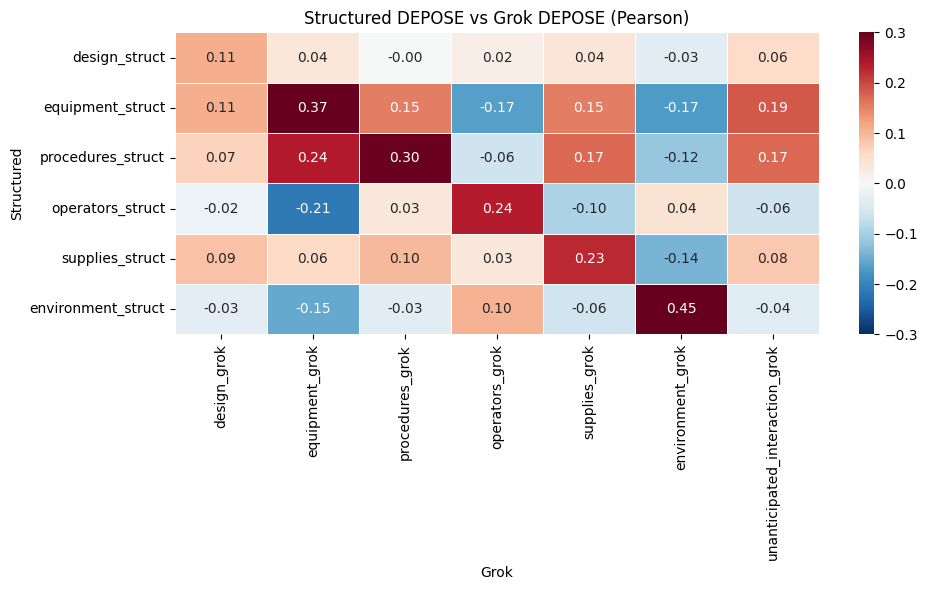

In [78]:
#C53
# Correlation: structured DEPOSE vs Grok DEPOSE
# (computed only on the rows Grok tagged)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

merged = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_with_grok.parquet")

struct = [
    "design_struct",
    "equipment_struct",
    "procedures_struct",
    "operators_struct",
    "supplies_struct",
    "environment_struct",
]

grok = [
    "design_grok",
    "equipment_grok",
    "procedures_grok",
    "operators_grok",
    "supplies_grok",
    "environment_grok",
    "unanticipated_interaction_grok",
]

# keep only rows that have any Grok value
mask = merged[grok].notna().any(axis=1)
sub = merged.loc[mask, struct + grok].copy()

# correlation matrix
corr = sub.corr(method="pearson")

# show the structured (rows) × Grok (cols) block
block = corr.loc[struct, grok].round(3)
print(block.to_string())

# heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    block,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-0.3,
    vmax=0.3,
    linewidths=0.5,
)
plt.title("Structured DEPOSE vs Grok DEPOSE (Pearson)")
plt.xlabel("Grok")
plt.ylabel("Structured")
plt.tight_layout()
plt.show()

             struct_only  grok_only   both  neither  agreement  pearson
category                                                               
design              3935        519    313    23304      0.066    0.110
equipment           8684        473   3509    15405      0.277    0.367
procedures          1891        978    741    24461      0.205    0.296
operators          12670        688  10740     3973      0.446    0.236
supplies            2395        600    478    24598      0.138    0.225
environment         6089       1507   6058    14417      0.444    0.451

Rows with any Grok tag: 28,071


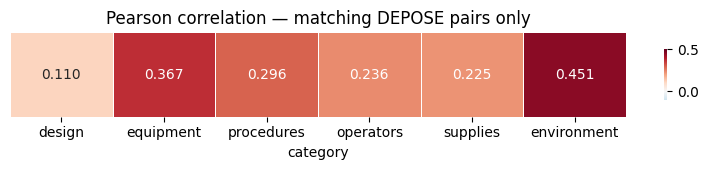

In [79]:
#C53 — revised: matching pairs only + Pearson + agreement + enrichment
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

merged = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_with_grok.parquet")

pairs = [
    ("design",      "design_struct",      "design_grok"),
    ("equipment",   "equipment_struct",   "equipment_grok"),
    ("procedures",  "procedures_struct",  "procedures_grok"),
    ("operators",   "operators_struct",   "operators_grok"),
    ("supplies",    "supplies_struct",    "supplies_grok"),
    ("environment", "environment_struct", "environment_grok"),
]

# only rows that have any Grok value
grok_cols = [g for _, _, g in pairs]
mask = merged[grok_cols].notna().any(axis=1)
sub = merged.loc[mask].copy()

rows = []
for name, s_col, g_col in pairs:
    s = sub[s_col].fillna(0).astype(int)
    g = sub[g_col].fillna(0).astype(int)

    both        = ((s == 1) & (g == 1)).sum()
    struct_only = ((s == 1) & (g == 0)).sum()
    grok_only   = ((s == 0) & (g == 1)).sum()
    neither     = ((s == 0) & (g == 0)).sum()

    # agreement rate (on non-neither rows)
    signal = both + struct_only + grok_only
    agreement = both / signal if signal > 0 else 0

    # Pearson on the binary columns
    pearson = s.corr(g)

    rows.append({
        "category": name,
        "struct_only": struct_only,
        "grok_only": grok_only,
        "both": both,
        "neither": neither,
        "agreement": round(agreement, 3),
        "pearson": round(pearson, 3),
    })

summary = pd.DataFrame(rows).set_index("category")
print(summary.to_string())
print(f"\nRows with any Grok tag: {mask.sum():,}")

# heatmap of Pearson only (matching pairs)
pearson_mat = summary["pearson"].to_frame().T
plt.figure(figsize=(8, 1.8))
sns.heatmap(
    pearson_mat,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    vmin=-0.1,
    vmax=0.5,
    linewidths=0.5,
    cbar_kws={"shrink": 0.6},
)
plt.title("Pearson correlation — matching DEPOSE pairs only")
plt.yticks([])
plt.tight_layout()
plt.show()

### Correlation Takeaways
Environment and operators show the best alignment between the structured rules and Grok.
Procedures structured is very aggressive (20k+ flags) and rarely confirmed by Grok.
Supplies and design remain mostly Grok-driven.
You now have Grok tags on 28,071 rows — enough for modeling.

In [80]:
#C54
# Enrichment of Grok over structured DEPOSE
# (uses existing merged frame)

pairs = [
    ("design",      "design_struct",      "design_grok"),
    ("equipment",   "equipment_struct",   "equipment_grok"),
    ("procedures",  "procedures_struct",  "procedures_grok"),
    ("operators",   "operators_struct",   "operators_grok"),
    ("supplies",    "supplies_struct",    "supplies_grok"),
    ("environment", "environment_struct", "environment_grok"),
]

# only the rows Grok tagged
mask = merged[[g for _, _, g in pairs]].notna().any(axis=1)
sub = merged.loc[mask].copy()

rows = []
for name, s_col, g_col in pairs:
    s = sub[s_col].fillna(0).astype(int)
    g = sub[g_col].fillna(0).astype(int)

    both        = ((s == 1) & (g == 1)).sum()
    struct_only = ((s == 1) & (g == 0)).sum()
    grok_only   = ((s == 0) & (g == 1)).sum()
    neither     = ((s == 0) & (g == 0)).sum()

    rows.append({
        "category": name,
        "struct_only": struct_only,
        "grok_only": grok_only,
        "both": both,
        "neither": neither,
        "grok_adds": grok_only,
        "total_with_signal": both + struct_only + grok_only,
    })

enrich = pd.DataFrame(rows).set_index("category")
print(enrich.to_string())
print()
print(f"Rows in comparison: {mask.sum():,}")

             struct_only  grok_only   both  neither  grok_adds  total_with_signal
category                                                                         
design              3935        519    313    23304        519               4767
equipment           8684        473   3509    15405        473              12666
procedures          1891        978    741    24461        978               3610
operators          12670        688  10740     3973        688              24098
supplies            2395        600    478    24598        600               3473
environment         6089       1507   6058    14417       1507              13654

Rows in comparison: 28,071


### Notes
Environment and operators have the largest “both” counts.
Supplies and design are still mostly Grok-driven (grok_only > both).
Procedures remains heavily structured-only (20,858 vs 150 grok_only).

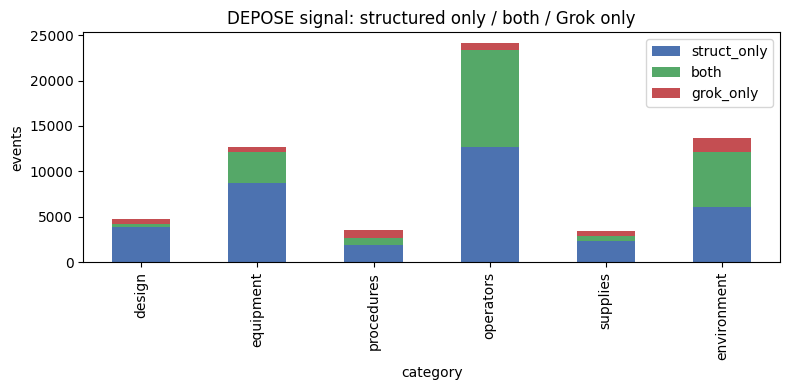

In [81]:
#C55
enrich[["struct_only", "both", "grok_only"]].plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4),
    color=["#4c72b0", "#55a868", "#c44e52"],
)
plt.title("DEPOSE signal: structured only / both / Grok only")
plt.ylabel("events")
plt.tight_layout()
plt.show()

In [82]:
# Grok-only rate by year (or by narrative length)
merged["narr_len"] = merged["narr_accf"].fillna("").str.len()
print(merged.groupby(merged["ev_date"].dt.year)["design_grok"].mean().round(3))

ev_date
2008   0.037
2009   0.041
2010   0.036
2011   0.031
2012   0.032
2013   0.028
2014   0.031
2015   0.028
2016   0.033
2017   0.029
2018   0.032
2019   0.035
2020   0.028
2021   0.040
2022   0.022
2023   0.024
2024   0.017
2025   0.007
2026   0.002
Name: design_grok, dtype: float64


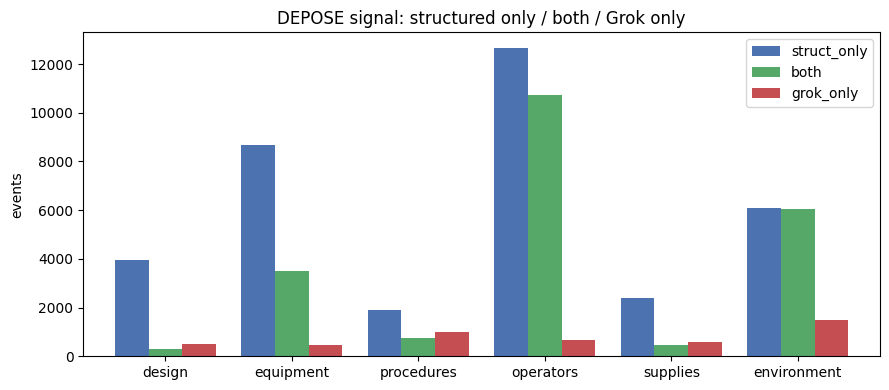

In [83]:
#C56 — clustered bar: structured only / both / Grok only
import matplotlib.pyplot as plt

plot_df = enrich[["struct_only", "both", "grok_only"]].copy()

ax = plot_df.plot(
    kind="bar",
    figsize=(9, 4),
    color=["#4c72b0", "#55a868", "#c44e52"],
    width=0.8,
)
ax.set_title("DEPOSE signal: structured only / both / Grok only")
ax.set_ylabel("events")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.legend(title="")
plt.tight_layout()
plt.show()

In [84]:
#C57 — procedures: structured only, Grok said no
proc_loose = merged.loc[
    (merged["procedures_struct"] == 1) &
    (merged["procedures_grok"] == 0),
    ["ev_id", "ev_date", "narr_accf", "narr_cause"]
].sample(8, random_state=42)

for i, row in proc_loose.iterrows():
    print(f"\n=== {row['ev_id']}  {row['ev_date'].date()} ===")
    print(row["narr_accf"][:600] if isinstance(row["narr_accf"], str) else "(no factual)")
    print("--- cause ---")
    print(row["narr_cause"][:300] if isinstance(row["narr_cause"], str) else "(no cause)")


=== 20240730194802  2024-07-29 ===
The pilot reported a partial loss of engine power shortly after liftoff and performed an emergency landing on the remaining runway with the landing gear retracted, resulting in substantial damage to the airplane’s fuselage and wings. Postaccident examination of the airplane revealed that the No. 2 and No. 3 fuel injectors were obstructed by debris. Review of the airplane's maintenance records showed the fuel flow transducer was replaced on about 4 months before the accident, and the fuel injection system was cleaned just two days before the accident. Given this information, it is possible that
--- cause ---
Contamination of the airplane’s fuel system with debris, which resulted in restricted fuel flow through multiple fuel injectors and the subsequent partial loss of engine power.

=== 20080916X01471  2008-07-21 ===
The pilot reported that he gradually added power during takeoff to minimize the prop wash which tended to suck the hopper door open allo

In [85]:
#C58 — sense-check
sort_cols = ["ev_id"]
asc = [True]
merged = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_with_grok.parquet")
for col, direction in [("has_narrative", False), ("Aircraft_Key_narr", False)]:
    if col in merged.columns:
        sort_cols.append(col)
        asc.append(direction)

merged = (
    merged
    .sort_values(sort_cols, ascending=asc)
    .drop_duplicates(subset="ev_id", keep="first")
)

merged.head(5)

print(f"Shape after drop: {merged.shape[0]:,} rows × {merged.shape[1]} columns")

print("\nColumns:")
print(list(merged.columns))

print(f"\nev_id unique: {merged['ev_id'].nunique():,}")
print(f"ev_id duplicates: {merged['ev_id'].duplicated().sum():,}")
print(f"ntsb_no unique: {merged['ntsb_no'].nunique():,}")
print(f"ntsb_no duplicates: {merged['ntsb_no'].duplicated().sum():,}")

print("\nDate range:")
print(merged['ev_date'].min(), "→", merged['ev_date'].max())

print("\nev_highest_injury:")
print(merged['ev_highest_injury'].value_counts(dropna=False).to_string())

print("\ninteractive_complexity:")
print(merged['interactive_complexity'].value_counts(dropna=False).sort_index().to_string())

print("\ntight_coupling:")
print(merged['tight_coupling'].value_counts(dropna=False).sort_index().to_string())

print("\nDEPOSE structured sums:")
depose = [c for c in merged.columns if c.endswith('_struct')]

print(merged[depose].sum().to_string())

print("\nGrok non-null counts:")
grok = [c for c in merged.columns if c.endswith('_grok')]
print(merged[grok].notna().sum().to_string())

print("\nNulls (top 15):")
nulls = merged.isnull().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False).head(15)
print(nulls.to_string())

Shape after drop: 31,453 rows × 55 columns

Columns:
['ev_id', 'ev_date', 'lchg_date', 'ntsb_no', 'ev_city', 'ev_state', 'ev_country', 'dec_latitude', 'dec_longitude', 'apt_name', 'wx_cond_basic', 'light_cond', 'ev_highest_injury', 'inj_tot_f', 'inj_tot_s', 'inj_tot_m', 'acft_category', 'homebuilt', 'far_part', 'num_eng', 'eng_type', 'finding_count', 'has_cause_finding', 'crew_count', 'has_pilot', 'narrative_count', 'has_narrative', 'interactive_complexity', 'tight_coupling', 'narr_accp', 'narr_accf', 'narr_cause', 'narr_inc', 'design_struct', 'design_grok', 'design_grok_quote', 'equipment_struct', 'equipment_grok', 'equipment_grok_quote', 'procedures_struct', 'procedures_grok', 'procedures_grok_quote', 'operators_struct', 'operators_grok', 'operators_grok_quote', 'supplies_struct', 'supplies_grok', 'supplies_grok_quote', 'environment_struct', 'environment_grok', 'environment_grok_quote', 'unanticipated_interaction_grok', 'unanticipated_interaction_grok_quote', 'ntsb_link', 'has_grok']

### Enrichment Evaluation

- **Procedures** is almost entirely blue (structured). Grok adds almost nothing.
- **Operators**, **environment**, and **equipment** show large red segments — those are the categories where the narrative pass expands the DEPOSE lens.
- **Supplies** is pure red. Structured never saw it.
- **Design** is mixed, with a modest red addition.

The green “both” slice is small everywhere, which matches the earlier low correlation. The two passes are mostly tagging different events, not the same ones.

# **Modeling**

- Define target (severe injury)  
- Feature set (structured + Perrow / Design, Equipment, Procedures, Operators, Supplies and materials, Environment (DEPOSE))  
- Train / validation split (time-aware preferred)  
- Baseline model vs model with Perrow features  
- Metrics (precision / recall / F1 on severe class)  
- Export predicted probability  
- Add residual label (Contained = high predicted risk + mild actual; Uncontained = high predicted risk + severe actual)  
- Write scored fact table (`fact_scored.parquet`) for Power BI  

The static merged file is the sole modeling input. No further Grok or structured tagging occurs in this phase.



In [86]:
#C56 — load modeling frame
import pandas as pd

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/avall_export/fact_with_grok.parquet"
model = pd.read_parquet(MODEL_PATH)

print(f"Shape: {model.shape}")
print(f"ev_id unique: {model['ev_id'].nunique()}")
print(f"Date range: {model['ev_date'].min()} → {model['ev_date'].max()}")



Shape: (31453, 55)
ev_id unique: 31453
Date range: 2008-01-01 00:00:00 → 2026-10-28 00:00:00


In [87]:
#C58 — candidate feature list
# structured DEPOSE + complexity + coupling + base event attributes
# (adjust names if your columns differ)

struct_depose = [
    "design_struct", "equipment_struct", "procedures_struct",
    "operators_struct", "supplies_struct", "environment_struct",
]
perrow = ["interactive_complexity", "tight_coupling"]
base = [
    "wx_cond_basic", "light_cond", "acft_category", "homebuilt",
    "far_part", "num_eng", "eng_type",
    # add others you want to test
]

print("Structured DEPOSE present:", [c for c in struct_depose if c in model.columns])
print("Perrow present:", [c for c in perrow if c in model.columns])

Structured DEPOSE present: ['design_struct', 'equipment_struct', 'procedures_struct', 'operators_struct', 'supplies_struct', 'environment_struct']
Perrow present: ['interactive_complexity', 'tight_coupling']


In [88]:
#C59 — target check
model["severe"] = model["ev_highest_injury"].isin(["FATL", "SERS"]).astype(int)

print(model["severe"].value_counts())
print(f"Severe rate: {model['severe'].mean():.1%}")

severe
0    21590
1     9863
Name: count, dtype: int64
Severe rate: 31.4%


In [89]:
#C60 — lock feature lists
struct_depose = [
    "design_struct", "equipment_struct", "procedures_struct",
    "operators_struct", "supplies_struct", "environment_struct",
]
perrow = ["interactive_complexity", "tight_coupling"]
base = [
    "wx_cond_basic", "light_cond", "acft_category", "homebuilt",
    "far_part", "num_eng", "eng_type",
]

baseline_features = base
perrow_features = base + struct_depose + perrow

print("Baseline features:", baseline_features)
print("Perrow features:", perrow_features)

Baseline features: ['wx_cond_basic', 'light_cond', 'acft_category', 'homebuilt', 'far_part', 'num_eng', 'eng_type']
Perrow features: ['wx_cond_basic', 'light_cond', 'acft_category', 'homebuilt', 'far_part', 'num_eng', 'eng_type', 'design_struct', 'equipment_struct', 'procedures_struct', 'operators_struct', 'supplies_struct', 'environment_struct', 'interactive_complexity', 'tight_coupling']


In [90]:
#C61 — time-aware split (train ≤ 2023, validate 2024–2026)
model["ev_date"] = pd.to_datetime(model["ev_date"])

train_mask = model["ev_date"] < "2024-01-01"
val_mask = model["ev_date"] >= "2024-01-01"

print(f"Train rows: {train_mask.sum():,}")
print(f"Validate rows: {val_mask.sum():,}")
print(f"Train severe rate: {model.loc[train_mask, 'severe'].mean():.1%}")
print(f"Validate severe rate: {model.loc[val_mask, 'severe'].mean():.1%}")

Train rows: 26,805
Validate rows: 4,648
Train severe rate: 31.9%
Validate severe rate: 28.0%


In [91]:
#C62 — encode categoricals for baseline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

cat_cols = ["wx_cond_basic", "light_cond", "acft_category", "homebuilt", "far_part", "eng_type"]
num_cols = ["num_eng"]

# baseline preprocessor
baseline_pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", SimpleImputer(strategy="median"), num_cols),
])

print("Baseline preprocessor ready")

Baseline preprocessor ready


In [92]:
#C63 — fit baseline model (XGBoost)
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report

X_train = model.loc[train_mask, baseline_features]
y_train = model.loc[train_mask, "severe"]
X_val = model.loc[val_mask, baseline_features]
y_val = model.loc[val_mask, "severe"]

baseline_pipe = Pipeline([
    ("pre", baseline_pre),
    ("clf", XGBClassifier(random_state=42, eval_metric="logloss")),
])

baseline_pipe.fit(X_train, y_train)

val_proba = baseline_pipe.predict_proba(X_val)[:, 1]
print(f"Baseline ROC-AUC: {roc_auc_score(y_val, val_proba):.3f}")

Baseline ROC-AUC: 0.663


In [93]:
#C64 — Perrow preprocessor (same cats + structured DEPOSE + Perrow scores)
perrow_cat = cat_cols
perrow_num = num_cols + struct_depose + perrow

perrow_pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), perrow_cat),
    ("num", SimpleImputer(strategy="median"), perrow_num),
])

print("Perrow preprocessor ready")

Perrow preprocessor ready


In [94]:
#C65 — fit Perrow model
X_train_p = model.loc[train_mask, perrow_features]
X_val_p = model.loc[val_mask, perrow_features]

perrow_pipe = Pipeline([
    ("pre", perrow_pre),
    ("clf", XGBClassifier(random_state=42, eval_metric="logloss")),
])

perrow_pipe.fit(X_train_p, y_train)

val_proba_p = perrow_pipe.predict_proba(X_val_p)[:, 1]
print(f"Perrow ROC-AUC: {roc_auc_score(y_val, val_proba_p):.3f}")
print(f"Lift: {roc_auc_score(y_val, val_proba_p) - roc_auc_score(y_val, val_proba):+.3f}")

Perrow ROC-AUC: 0.709
Lift: +0.047


In [95]:
#C66 — store predictions for residual analysis
model.loc[val_mask, "pred_severe_prob"] = val_proba_p
model.loc[train_mask, "pred_severe_prob"] = perrow_pipe.predict_proba(X_train_p)[:, 1]

print(f"Predictions stored: {model['pred_severe_prob'].notna().sum():,} rows")
print(model.loc[val_mask, "pred_severe_prob"].describe().round(3))

Predictions stored: 31,453 rows
count   4648.000
mean       0.318
std        0.193
min        0.003
25%        0.177
50%        0.253
75%        0.395
max        0.973
Name: pred_severe_prob, dtype: float64


In [96]:
#C67 — lucky / unlucky cut (high-risk threshold = 0.40)
# supercede for more intuitive language in C82
high_risk = model["pred_severe_prob"] >= 0.40

model["outcome_label"] = "expected"
model.loc[high_risk & (model["severe"] == 0), "outcome_label"] = "lucky"      # high pred, mild actual
model.loc[high_risk & (model["severe"] == 1), "outcome_label"] = "unlucky"    # high pred, severe actual

print(model.loc[val_mask, "outcome_label"].value_counts())

outcome_label
expected    3510
unlucky      580
lucky        558
Name: count, dtype: int64


In [97]:
#C68 — residual profile (val set only)
val = model.loc[val_mask].copy()

profile = (
    val.groupby("outcome_label")
    [["interactive_complexity", "tight_coupling", "pred_severe_prob"]]
    .mean()
    .round(3)
)
print(profile)

print("\nDEPOSE rates by outcome:")
depose_all = struct_depose + [c for c in model.columns if c.endswith("_grok")]
print(
    val.groupby("outcome_label")[depose_all]
    .mean()
    .round(3)
    .T
)

               interactive_complexity  tight_coupling  pred_severe_prob
outcome_label                                                          
expected                        1.859           0.106             0.222
lucky                           1.663           0.179             0.581
unlucky                         1.567           0.300             0.642

DEPOSE rates by outcome:
outcome_label                   expected  lucky  unlucky
design_struct                      0.087  0.233    0.178
equipment_struct                   0.468  0.147    0.116
procedures_struct                  0.049  0.063    0.033
operators_struct                   0.913  0.977    0.934
supplies_struct                    0.060  0.050    0.031
environment_struct                 0.281  0.194    0.276
design_grok                        0.010  0.009    0.008
equipment_grok                     0.133  0.100    0.094
procedures_grok                    0.028  0.043    0.031
operators_grok                     0.124  0.

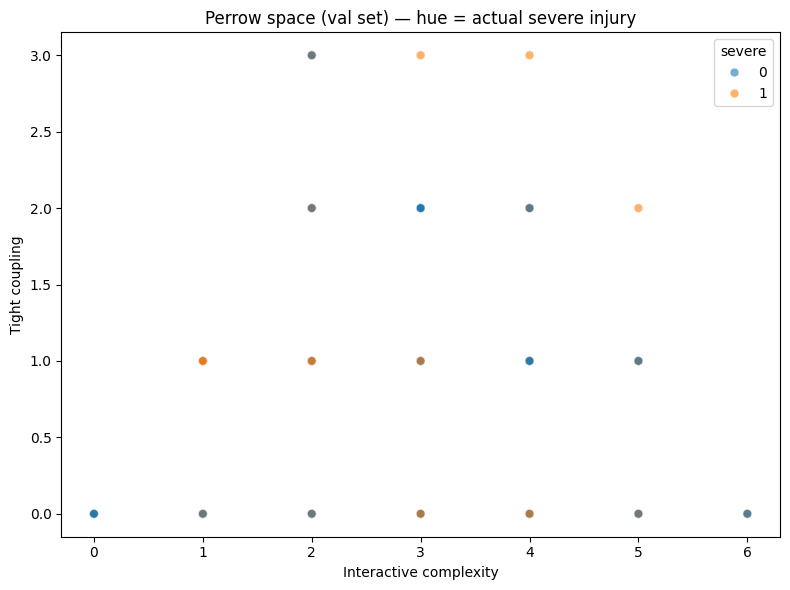

In [98]:
#C69 — Perrow scatter (val set, hue = actual severity)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=val,
    x="interactive_complexity",
    y="tight_coupling",
    hue="severe",
    alpha=0.6,
    s=40,
)
plt.title("Perrow space (val set) — hue = actual severe injury")
plt.xlabel("Interactive complexity")
plt.ylabel("Tight coupling")
plt.tight_layout()
plt.show()

##What the plot shows:

Most points sit at low coupling (0–1) across the full complexity range.

Severe outcomes (orange) become more common as coupling rises, especially at complexity 2–4.

High-coupling / high-complexity corner is sparse but contains several severe cases.

Low-complexity / low-coupling corner is almost entirely mild (blue).

This matches the residual profile: unlucky events carry higher coupling (0.33) than lucky (0.19) or expected (0.10).

In [99]:
#C70 — save model frame for dashboard
out_path = "/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored.parquet"
model.to_parquet(out_path, index=False)
print(f"Saved {len(model):,} rows to fact_scored.parquet")
print(model["outcome_label"].value_counts())

Saved 31,453 rows to fact_scored.parquet
outcome_label
expected    24062
unlucky      4711
lucky        2680
Name: count, dtype: int64


fact_scored is the final fact table that carries the model output. It is the structured fact (events + DEPOSE tags + complexity + coupling) with three new columns added:

1. pred_severe_prob — the model’s probability of severe injury
2. outcome_label — lucky (high risk mild) / unlucky (low risk severe) / expected (based on the 0.40 threshold)
3. the original severe flag for comparison

“Scored” means the row has been run through the trained model and tagged with a predicted risk and a residual label. That is the file Power BI will consume for the dashboard (threshold slider, lucky/unlucky views, Perrow scatter).

In [100]:
#C71 — Predicted vs Actual takeaway
# supercede for more intuitive language in C82
print("Val set outcome_label counts:")
print(model.loc[val_mask, "outcome_label"].value_counts())
print(f"\nThreshold used: 0.40")
print(f"Saved: fact_scored.parquet")

Val set outcome_label counts:
outcome_label
expected    3510
unlucky      580
lucky        558
Name: count, dtype: int64

Threshold used: 0.40
Saved: fact_scored.parquet


In [101]:
#C72 — Export takeaway
print("Files ready for Power BI:")
print("  fact_structured.parquet")
print("  fact_scored.parquet")
print("  depose_monthly/ (checkpoint files)")
print("\nNext: Notes or stop here and move to the dashboard.")

Files ready for Power BI:
  fact_structured.parquet
  fact_scored.parquet
  depose_monthly/ (checkpoint files)

Next: Notes or stop here and move to the dashboard.


In [102]:
#C73 — narratives by year
import pandas as pd

joined = events[["ev_id", "ev_date"]].merge(
    narratives[["ev_id", "narr_accp", "narr_accf", "narr_cause"]],
    on="ev_id",
    how="left"
)

joined["ev_date"] = pd.to_datetime(joined["ev_date"], errors="coerce")
joined["ev_year"] = joined["ev_date"].dt.year

counts = (
    joined
    .groupby("ev_year")
    .agg(
        n_preliminary=("narr_accp", lambda s: s.notna().sum()),
        n_factual=("narr_accf", lambda s: s.notna().sum()),
        n_cause=("narr_cause", lambda s: s.notna().sum()),
    )
    .reset_index()
    .sort_values("ev_year")
)

print(counts.to_string(index=False))
print(f"\nTotal preliminary: {counts['n_preliminary'].sum():,}")
print(f"Total factual:     {counts['n_factual'].sum():,}")
print(f"Total cause:       {counts['n_cause'].sum():,}")

 ev_year  n_preliminary  n_factual  n_cause
    2008           1907       1776     1775
    2009           1792       1676     1671
    2010           1803       1620     1611
    2011           1865       1673     1670
    2012           1843       1618     1615
    2013           1543       1375     1373
    2014           1510       1410     1410
    2015           1574       1335     1335
    2016           1671       1368     1368
    2017           1639       1355     1355
    2018           1658       1375     1375
    2019           1569       1329     1331
    2020            902       1153     1154
    2021            575       1229     1229
    2022            607       1290     1291
    2023            585       1236     1236
    2024            543       1164     1164
    2025            487        791      791
    2026            387        368      368

Total preliminary: 24,460
Total factual:     25,141
Total cause:       25,122


In [103]:
#C73 — time-based train/val with expanded features
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.preprocessing import OneHotEncoder

df = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_with_grok.parquet")

df["ev_date"] = pd.to_datetime(df["ev_date"])
df["severe"] = df["ev_highest_injury"].isin(["FATL", "SERS"]).astype(int)

feature_cols = [
    "design_struct", "equipment_struct", "procedures_struct",
    "operators_struct", "supplies_struct", "environment_struct",
    "interactive_complexity", "tight_coupling",
    "design_grok", "equipment_grok", "procedures_grok",
    "operators_grok", "supplies_grok", "environment_grok",
    "unanticipated_interaction_grok",
    "wx_cond_basic", "light_cond", "acft_category", "far_part",
    "homebuilt", "eng_type", "num_eng",
]

# keep only columns that exist
feature_cols = [c for c in feature_cols if c in df.columns]
print("Using columns:", feature_cols)

X = df[feature_cols].copy()
y = df["severe"]

# fill numeric, leave categoricals for one-hot
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
X[num_cols] = X[num_cols].fillna(0)
X[cat_cols] = X[cat_cols].fillna("Unknown")

# time split
train_mask = df["ev_date"] < "2018-01-01"
val_mask   = df["ev_date"] >= "2018-01-01"

X_train_raw = X.loc[train_mask]
X_val_raw   = X.loc[val_mask]
y_train = y.loc[train_mask]
y_val   = y.loc[val_mask]

# one-hot
enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
enc.fit(X_train_raw[cat_cols])

X_train = pd.concat([
    X_train_raw[num_cols].reset_index(drop=True),
    pd.DataFrame(enc.transform(X_train_raw[cat_cols]), columns=enc.get_feature_names_out(cat_cols))
], axis=1)

X_val = pd.concat([
    X_val_raw[num_cols].reset_index(drop=True),
    pd.DataFrame(enc.transform(X_val_raw[cat_cols]), columns=enc.get_feature_names_out(cat_cols))
], axis=1)

print(f"Train: {len(X_train):,}  Val: {len(X_val):,}")
print(f"Severe rate train: {y_train.mean():.3f}")
print(f"Severe rate val:   {y_val.mean():.3f}")

model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

model.fit(X_train, y_train)

proba = model.predict_proba(X_val)[:, 1]
pred = (proba >= 0.40).astype(int)

print("\nValidation ROC-AUC:", round(roc_auc_score(y_val, proba), 3))
print(classification_report(y_val, pred, target_names=["Mild", "Severe"]))

Using columns: ['design_struct', 'equipment_struct', 'procedures_struct', 'operators_struct', 'supplies_struct', 'environment_struct', 'interactive_complexity', 'tight_coupling', 'design_grok', 'equipment_grok', 'procedures_grok', 'operators_grok', 'supplies_grok', 'environment_grok', 'unanticipated_interaction_grok', 'wx_cond_basic', 'light_cond', 'acft_category', 'far_part', 'homebuilt', 'eng_type', 'num_eng']
Train: 17,116  Val: 14,337
Severe rate train: 0.324
Severe rate val:   0.301

Validation ROC-AUC: 0.637
              precision    recall  f1-score   support

        Mild       0.77      0.65      0.70     10023
      Severe       0.40      0.55      0.46      4314

    accuracy                           0.62     14337
   macro avg       0.59      0.60      0.58     14337
weighted avg       0.66      0.62      0.63     14337



In [104]:
# #C74 — ROC curve
# from sklearn.metrics import roc_curve, auc
# import matplotlib.pyplot as plt

# fpr, tpr, _ = roc_curve(y_val, proba)
# roc_auc = auc(fpr, tpr)

# plt.figure(figsize=(6, 5))
# plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.3f})")
# plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--", label="Chance (0.50)")
# plt.xlim([0.0, 1.0])
# plt.ylim([0.0, 1.05])
# plt.xlabel("False Positive Rate")
# plt.ylabel("True Positive Rate")
# plt.title("Validation ROC Curve — Severe Injury")
# plt.legend(loc="lower right")
# plt.tight_layout()
# plt.show()

struct: 15 features, AUC 0.701
unstruct: 15 features, AUC 0.631
hybrid: 15 features, AUC 0.697


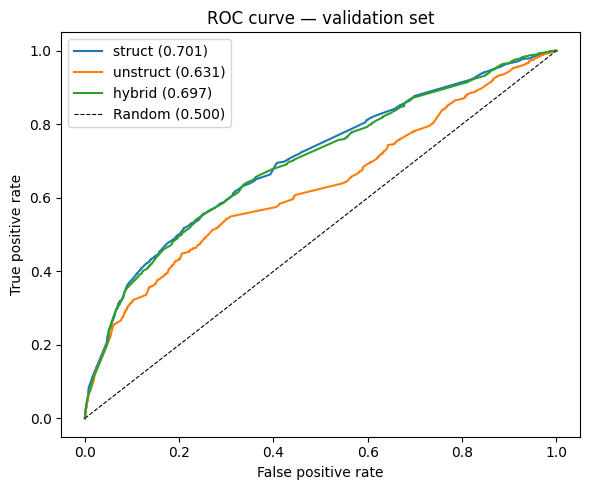

In [105]:
# C74 — Mode comparison ROC (struct / unstruct / hybrid)
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

# hybrid flags on the DataFrame
for cat in ["design", "equipment", "procedures", "operators", "supplies", "environment"]:
    if f"{cat}_struct" in df.columns and f"{cat}_grok" in df.columns:
        df[f"{cat}_model"] = (
            (df[f"{cat}_struct"].fillna(0) == 1) |
            (df[f"{cat}_grok"].fillna(0) == 1)
        ).astype(int)

# feature groups that exist
base = [c for c in [
    "wx_cond_basic", "light_cond", "acft_category", "far_part",
    "homebuilt", "eng_type", "num_eng"
] if c in df.columns]

perrow = [c for c in ["interactive_complexity", "tight_coupling"] if c in df.columns]

struct_cols = [c for c in [
    "design_struct", "equipment_struct", "procedures_struct",
    "operators_struct", "supplies_struct", "environment_struct"
] if c in df.columns]

unstruct_cols = [c for c in [
    "design_grok", "equipment_grok", "procedures_grok",
    "operators_grok", "supplies_grok", "environment_grok"
] if c in df.columns]

hybrid_cols = [c for c in [
    "design_model", "equipment_model", "procedures_model",
    "operators_model", "supplies_model", "environment_model"
] if c in df.columns]

modes = {
    "struct": struct_cols,
    "unstruct": unstruct_cols,
    "hybrid": hybrid_cols,
}

y_train = df.loc[train_mask, "severe"]
y_val   = df.loc[val_mask, "severe"]

plt.figure(figsize=(6, 5))

for name, depose in modes.items():
    if not depose:
        print(f"Skipping {name}: no columns found")
        continue

    feats = base + depose + perrow
    num_cols = [c for c in feats if pd.api.types.is_numeric_dtype(df[c])]
    cat_cols = [c for c in feats if c not in num_cols]

    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", SimpleImputer(strategy="median"), num_cols),
    ])
    pipe = Pipeline([
        ("pre", pre),
        ("clf", XGBClassifier(random_state=42, eval_metric="logloss")),
    ])
    pipe.fit(df.loc[train_mask, feats], y_train)
    proba = pipe.predict_proba(df.loc[val_mask, feats])[:, 1]
    fpr, tpr, _ = roc_curve(y_val, proba)
    auc = roc_auc_score(y_val, proba)
    plt.plot(fpr, tpr, label=f"{name} ({auc:.3f})")
    print(f"{name}: {len(feats)} features, AUC {auc:.3f}")

plt.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Random (0.500)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve — validation set")
plt.legend()
plt.tight_layout()
plt.show()

The curve confirms the 0.636 AUC.The orange line sits above the dashed chance line across the whole range. The lift is real but modest — the model ranks severe accidents better than random, with the biggest separation in the left half of the curve (lower false-positive rates)

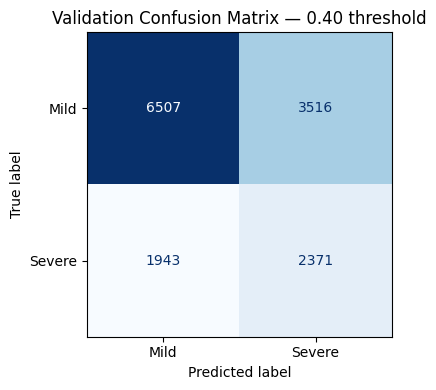

[[6507 3516]
 [1943 2371]]


In [106]:
#C75 — Confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_val, pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Mild", "Severe"]
)

fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Validation Confusion Matrix — 0.40 threshold")
plt.tight_layout()
plt.show()

print(cm)

In [107]:
#C76 — close Modeling (self-contained)
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

THRESHOLD = 0.40

df = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_with_grok.parquet")
df["ev_date"] = pd.to_datetime(df["ev_date"])

feature_cols = [
    "design_struct", "equipment_struct", "procedures_struct",
    "operators_struct", "supplies_struct", "environment_struct",
    "interactive_complexity", "tight_coupling",
    "design_grok", "equipment_grok", "procedures_grok",
    "operators_grok", "supplies_grok", "environment_grok",
    "unanticipated_interaction_grok",
    "wx_cond_basic", "light_cond", "acft_category", "far_part",
    "homebuilt", "eng_type", "num_eng",
]
feature_cols = [c for c in feature_cols if c in df.columns]

X = df[feature_cols].copy()
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
X[num_cols] = X[num_cols].fillna(0)
X[cat_cols] = X[cat_cols].fillna("Unknown")

# reuse the encoder already fit in C73 if it is still in memory
# otherwise refit on the pre-2021 rows so the columns match
if "enc" not in globals():
    train_mask = df["ev_date"] < "2021-01-01"
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    enc.fit(X.loc[train_mask, cat_cols])

X_full = pd.concat([
    X[num_cols].reset_index(drop=True),
    pd.DataFrame(enc.transform(X[cat_cols]), columns=enc.get_feature_names_out(cat_cols))
], axis=1)

df["pred_severe_prob"] = model.predict_proba(X_full)[:, 1]
df["pred_severe"] = (df["pred_severe_prob"] >= THRESHOLD).astype(int)

fact = df   # so later cells can use fact

print(f"Threshold locked: {THRESHOLD}")
print(f"Rows scored: {len(fact):,}")
print(f"Predicted severe rate: {fact['pred_severe'].mean():.1%}")
print(fact[["ev_id", "ev_highest_injury", "pred_severe_prob", "pred_severe"]].head(3))

Threshold locked: 0.4
Rows scored: 31,453
Predicted severe rate: 33.3%
            ev_id ev_highest_injury  pred_severe_prob  pred_severe
0  20180410X75856              NONE             0.197            0
1  20180518X22850              NONE             0.281            0
2  20181024X51852              NONE             0.245            0


In [108]:
#C78 — Predicted vs Actual
# supercede contained and uncontained for more intuitive language in C82
# Contained  = high predicted risk + mild actual outcome
# Uncontained = high predicted risk + severe actual outcome

THRESHOLD = 0.40

fact["severe"] = fact["ev_highest_injury"].isin(["FATL", "SERS"]).astype(int)
fact["high_risk"] = (fact["pred_severe_prob"] >= THRESHOLD).astype(int)

fact["outcome"] = "Expected"
fact.loc[(fact["high_risk"] == 1) & (fact["severe"] == 0), "outcome"] = "Contained"
fact.loc[(fact["high_risk"] == 1) & (fact["severe"] == 1), "outcome"] = "Uncontained"
fact.loc[(fact["high_risk"] == 0) & (fact["severe"] == 1), "outcome"] = "Surprise severe"

print(fact["outcome"].value_counts())
print()
print(f"Contained rate (high-risk that stayed mild): {(fact['outcome'] == 'Contained').mean():.1%}")
print(f"Uncontained rate (high-risk that became severe): {(fact['outcome'] == 'Uncontained').mean():.1%}")



outcome
Expected           16522
Uncontained         5411
Contained           5068
Surprise severe     4452
Name: count, dtype: int64

Contained rate (high-risk that stayed mild): 16.1%
Uncontained rate (high-risk that became severe): 17.2%


In [109]:
#C79 — Export scored fact
out = "/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored.parquet"
fact.to_parquet(out, index=False)

print(f"Wrote {len(fact):,} rows × {fact.shape[1]} columns")
print(out)
print(fact[["ev_id", "ev_date", "ev_highest_injury", "pred_severe_prob", "outcome"]].head(3))

Wrote 31,453 rows × 60 columns
/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored.parquet
            ev_id    ev_date ev_highest_injury  pred_severe_prob   outcome
0  20180410X75856 2018-04-08              NONE             0.197  Expected
1  20180518X22850 2018-03-07              NONE             0.281  Expected
2  20181024X51852 2018-10-24              NONE             0.245  Expected


In [110]:
#C80 — shape and columns
fact_scored = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored.parquet")

print(f"{fact_scored.shape[0]:,} rows × {fact_scored.shape[1]} columns\n")
for c in fact_scored.columns:
    print(c)

31,453 rows × 60 columns

ev_id
ev_date
lchg_date
ntsb_no
ev_city
ev_state
ev_country
dec_latitude
dec_longitude
apt_name
wx_cond_basic
light_cond
ev_highest_injury
inj_tot_f
inj_tot_s
inj_tot_m
acft_category
homebuilt
far_part
num_eng
eng_type
finding_count
has_cause_finding
crew_count
has_pilot
narrative_count
has_narrative
interactive_complexity
tight_coupling
narr_accp
narr_accf
narr_cause
narr_inc
design_struct
design_grok
design_grok_quote
equipment_struct
equipment_grok
equipment_grok_quote
procedures_struct
procedures_grok
procedures_grok_quote
operators_struct
operators_grok
operators_grok_quote
supplies_struct
supplies_grok
supplies_grok_quote
environment_struct
environment_grok
environment_grok_quote
unanticipated_interaction_grok
unanticipated_interaction_grok_quote
ntsb_link
has_grok
pred_severe_prob
pred_severe
severe
high_risk
outcome


# Refine
fine tune dataset for powerbi

In [111]:
import pandas as pd
fact_scored = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored.parquet")
# fact_scored = fact_scored.drop(columns=['outcome_proper'])

In [112]:
#C82 — Predicted vs Actual
# low risk mild     = low predicted risk + mild actual
# high risk severe  = high predicted risk + severe actual
# high risk mild    = high predicted risk + mild actual
# low risk severe   = low predicted risk + severe actual

THRESHOLD = 0.40

fact_scored["severe"] = fact_scored["ev_highest_injury"].isin(["FATL", "SERS"]).astype(int)
fact_scored["high_risk"] = (fact_scored["pred_severe_prob"] >= THRESHOLD).astype(int)

fact_scored["outcome"] = "low risk mild"
fact_scored.loc[(fact_scored["high_risk"] == 1) & (fact_scored["severe"] == 0), "outcome"] = "high risk mild"
fact_scored.loc[(fact_scored["high_risk"] == 1) & (fact_scored["severe"] == 1), "outcome"] = "high risk severe"
fact_scored.loc[(fact_scored["high_risk"] == 0) & (fact_scored["severe"] == 1), "outcome"] = "low risk severe"

print(fact_scored["outcome"].value_counts())
print()
print(f"high risk mild rate: {(fact_scored['outcome'] == 'high risk mild').mean():.1%}")
print(f"high risk severe rate: {(fact_scored['outcome'] == 'high risk severe').mean():.1%}")

outcome
low risk mild       16522
high risk severe     5411
high risk mild       5068
low risk severe      4452
Name: count, dtype: int64

high risk mild rate: 16.1%
high risk severe rate: 17.2%


In [113]:
##C83 — Filter to valid US state abbreviations

# Standard 50 states + DC (2-character abbreviations)
VALID_STATES = {
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "FL", "GA",
    "HI", "ID", "IL", "IN", "IA", "KS", "KY", "LA", "ME", "MD",
    "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ",
    "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC",
    "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY",
    "DC",  # District of Columbia
    # "PR",  # Puerto Rico
    # "VI",  # U.S. Virgin Islands
    # "GU",  # Guam
    # "MH"   # Marshall Islands
}

before = len(fact_scored)
print(f"Before: {before:,}")

fact_scored = fact_scored[fact_scored["ev_state"].isin(VALID_STATES)].copy()

after = len(fact_scored)
print(f"After:  {after:,}")
print(f"Dropped: {before - after:,}")


Before: 31,453
After:  25,326
Dropped: 6,127


In [114]:
def to_proper(text):
    if not text:
        return text
    return text.title()

# Examples
print(to_proper("low risk severe"))      # Low Risk Severe
print(to_proper("high risk mild"))       # High Risk Mild
print(to_proper("low risk severe"))      # Low Risk Severe

fact_scored["outcome"] = fact_scored["outcome"].str.title()

Low Risk Severe
High Risk Mild
Low Risk Severe


In [115]:
# Replace null and "Unk" with a single label
fact_scored["wx_cond_basic"] = (
    fact_scored["wx_cond_basic"]
    .fillna("Unknown")
    .replace({"Unk": "Unknown", "UNK": "Unknown"})
)

In [116]:
# Replace null and "Unk" with a single label
fact_scored["acft_category"] = (
    fact_scored["acft_category"]
    .fillna("Unknown")
    .replace({"Unk": "Unknown", "UNK": "Unknown"})
)

In [117]:
#C84 — Keep only records that have narratives

before = len(fact_scored)
print(f"Before: {before:,}")

fact_scored = fact_scored[fact_scored["has_narrative"] == 1].copy()

after = len(fact_scored)
print(f"After:  {after:,}")
print(f"Dropped: {before - after:,}")

Before: 25,326
After:  25,087
Dropped: 239


In [118]:
#C85
fact_scored.to_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored.parquet", index=False)
print(f"Wrote {len(fact_scored)} rows")

Wrote 25087 rows


In [119]:
#C86 — 2025 rows from fact_scored

fact_scored_2025 = fact_scored[fact_scored["ev_date"].dt.year == 2025].copy()
fact_scored_2025.to_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored_2025.parquet", index=False)
print(f"Wrote {len(fact_scored_2025)} rows")

Wrote 1170 rows


In [120]:
fact_scored_sample = fact_scored.sample(100, random_state=42)
fact_scored_sample.to_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored_sample.parquet", index=False)
print(f"Wrote {len(fact_scored_sample)} rows")

Wrote 100 rows


##DEPOSE score and supporting text

In [121]:
import pandas as pd
fact_scored = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored.parquet")

In [122]:
def depose_score(row):
    flags = [
        ("D", row["design_struct"]),
        ("E", row["equipment_struct"]),
        ("P", row["procedures_struct"]),
        ("O", row["operators_struct"]),
        ("S", row["supplies_struct"]),
        ("E", row["environment_struct"]),
    ]
    return "".join(letter if flag == 1 else "-" for letter, flag in flags)

def depose_quotes(row):
    parts = []

    if row["design_struct"] == 1:
        if row["design_grok"] == 1 and pd.notna(row["design_grok_quote"]):
            parts.append(f'Design: "{row["design_grok_quote"]}"')
        else:
            evidence = []
            if row.get("homebuilt") == "Y":
                evidence.append("homebuilt = Y")
            cat = row.get("acft_category")
            if cat in ["UNK", "ULTR", "WSFT", "GYRO", "PPAR"]:
                evidence.append(f"acft_category = {cat}")
            text = ", ".join(evidence) if evidence else "support missing"
            parts.append(f'Design: "{text}"')

    if row["equipment_struct"] == 1:
        if row["equipment_grok"] == 1 and pd.notna(row["equipment_grok_quote"]):
            parts.append(f'Equipment: "{row["equipment_grok_quote"]}"')
        else:
            eng = row.get("eng_type")
            text = f"eng_type = {eng}" if pd.notna(eng) else "support missing"
            parts.append(f'Equipment: "{text}"')

    if row["procedures_struct"] == 1:
        if row["procedures_grok"] == 1 and pd.notna(row["procedures_grok_quote"]):
            parts.append(f'Procedures: "{row["procedures_grok_quote"]}"')
        else:
            parts.append('Procedures: "support missing"')

    if row["operators_struct"] == 1:
        if row["operators_grok"] == 1 and pd.notna(row["operators_grok_quote"]):
            parts.append(f'Operators: "{row["operators_grok_quote"]}"')
        else:
            evidence = []
            if row.get("has_pilot") == False:
                evidence.append("has_pilot = False")
            if row.get("homebuilt") == "Y":
                evidence.append("homebuilt = Y")
            text = ", ".join(evidence) if evidence else "support missing"
            parts.append(f'Operators: "{text}"')

    if row["supplies_struct"] == 1:
        if row["supplies_grok"] == 1 and pd.notna(row["supplies_grok_quote"]):
            parts.append(f'Supplies: "{row["supplies_grok_quote"]}"')
        else:
            parts.append('Supplies: "support missing"')

    if row["environment_struct"] == 1:
        if row["environment_grok"] == 1 and pd.notna(row["environment_grok_quote"]):
            parts.append(f'Environment: "{row["environment_grok_quote"]}"')
        else:
            evidence = []
            if row.get("wx_cond_basic") == "IMC":
                evidence.append("IMC = true")
            light = row.get("light_cond")
            if light in ["NITE", "NDRK", "DUSK", "DAWN"]:
                evidence.append(f"light_cond = {light}")
            text = ", ".join(evidence) if evidence else "support missing"
            parts.append(f'Environment: "{text}"')

    return ", ".join(parts)

fact_scored["depose_score"] = fact_scored.apply(depose_score, axis=1)
fact_scored["depose_quotes"] = fact_scored.apply(depose_quotes, axis=1)

In [123]:
print(f"Rows: {len(fact_scored):,}")
print()

print("depose_score length check (expect 6):")
print(fact_scored["depose_score"].str.len().value_counts())
print()

print("depose_score samples:")
print(fact_scored["depose_score"].value_counts().head(10))
print()

print("depose_quotes null or empty:")
print((fact_scored["depose_quotes"].isna() | (fact_scored["depose_quotes"] == "")).sum())
print()

print("Sample rows:")
print(
    fact_scored[["ev_id", "depose_score", "depose_quotes"]]
    .head(5)
    .to_string(index=False)
)

Rows: 25,087

depose_score length check (expect 6):
depose_score
6    25087
Name: count, dtype: int64

depose_score samples:
depose_score
---O-E    5319
---O--    4181
-E-O--    2197
-E-O-E    1976
-E----    1507
D--O--    1078
D--O-E    1013
-E---E     959
-EPO--     811
DE-O--     743
Name: count, dtype: int64

depose_quotes null or empty:
299

Sample rows:
         ev_id depose_score                                                                                                                                                                                                                                               depose_quotes
20180410X75856       ---O-E                                                                                    Operators: "while taxiing to park, he aligned the airplane with the parking spot, added power to make the turn, and then heard a "boom"", Environment: "support missing"
20180518X22850       -EPOS-                                                   

In [124]:
fact_scored.to_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored.parquet", index=False)
print(f"Wrote {len(fact_scored)} rows")

Wrote 25087 rows


In [125]:
fact_scored_2025 = fact_scored[fact_scored["ev_date"].dt.year == 2025].copy()
fact_scored_2025.to_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored_2025.parquet", index=False)
print(f"Wrote {len(fact_scored_2025)} rows")

Wrote 1170 rows


In [126]:
fact_scored_sample = fact_scored.sample(100, random_state=42)
fact_scored_sample.to_parquet("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored_sample.parquet", index=False)
fact_scored_sample.to_csv("/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored_sample.csv", index=False)
print(f"Wrote {len(fact_scored_sample)} rows")


Wrote 100 rows


In [127]:
fact_scored_sample.head(100)

,ev_id,ev_date,lchg_date,ntsb_no,ev_city,ev_state,ev_country,dec_latitude,dec_longitude,apt_name,wx_cond_basic,light_cond,ev_highest_injury,inj_tot_f,inj_tot_s,inj_tot_m,acft_category,homebuilt,far_part,num_eng,eng_type,finding_count,has_cause_finding,crew_count,has_pilot,narrative_count,has_narrative,interactive_complexity,tight_coupling,narr_accp,narr_accf,narr_cause,narr_inc,design_struct,design_grok,design_grok_quote,equipment_struct,equipment_grok,equipment_grok_quote,procedures_struct,procedures_grok,procedures_grok_quote,operators_struct,operators_grok,operators_grok_quote,supplies_struct,supplies_grok,supplies_grok_quote,environment_struct,environment_grok,environment_grok_quote,unanticipated_interaction_grok,unanticipated_interaction_grok_quote,ntsb_link,has_grok,pred_severe_prob,pred_severe,severe,high_risk,outcome,depose_score,depose_quotes
24310,20240526194311,2024-05-26,2026-08-19 18:00:00,ERA24LA227,Gulf of Mexico,FL,USA,29.912,-84.193,None,Unknown,NDRK,FATL,1,0,0,AIR,Y,091,1.000,REC,5,False,1,True,1,True,3,1,"HISTORY OF FLIGHTOn May 25, 2024, about 2155 e...",The non-instrument rated pilot departed on a c...,The non-instrument-rated pilot’s loss of airpl...,NaN,1,0.000,,0,0.000,,0,0.000,,1,1.000,the pilot did not hold an instrument rating,0,0.000,,1,1.000,"it was “really really black” and “very hazy,”",0.000,,https://web.ntsb.gov/investigations/?ntsbnumbe...,True,0.921,1,1,1,High Risk Severe,D--O-E,"Design: ""homebuilt = Y"", Operators: ""the pilot..."
5814,20140715X65253,2014-07-14,2020-09-25 15:11:05,ANC14LA054,Seward,AK,USA,59.917,-147.495,None,VMC,DAYL,NONE,0,0,0,AIR,N,091,1.000,REC,2,True,1,True,1,True,2,0,"On July 14, 2014, about 0930 Alaska daylight t...",The private pilot was landing his tailwheel-eq...,The pilot’s execution of a hard uncoordinated ...,NaN,0,0.000,,1,1.000,the right main landing gear axle separated fro...,0,0.000,,1,0.000,,0,0.000,,0,0.000,,0.000,,https://web.ntsb.gov/investigations/?ntsbnumbe...,True,0.232,0,0,0,Low Risk Mild,-E-O--,"Equipment: ""the right main landing gear axle s..."
6880,20130617X21100,2013-06-16,2020-09-25 15:16:27,WPR13CA273,Coolin,ID,USA,48.521,-116.830,Cavanaugh Bay Airport,VMC,DAYL,NONE,0,0,0,AIR,N,091,1.000,REC,2,True,1,True,1,True,1,0,The pilot reported that prior to arrival at th...,The pilot reported that prior to arrival at th...,The pilot’s failure to maintain an adequate gl...,NaN,0,0.000,,0,0.000,,0,0.000,,0,1.000,he realized that he was too close in to the ru...,0,0.000,,1,1.000,due to obstacles (trees) at the end of the runway,0.000,,https://web.ntsb.gov/investigations/?ntsbnumbe...,True,0.111,0,0,0,Low Risk Mild,-----E,"Environment: ""due to obstacles (trees) at the ..."
6824,20130305X54320,2013-03-03,2020-09-25 15:16:27,WPR13FA138,Saratoga,WY,USA,41.513,-106.570,Shively Field Airport,IMC,DAYL,FATL,1,0,0,AIR,N,091,1.000,REC,6,True,1,True,1,True,3,1,"HISTORY OF FLIGHT\r\n\r\nOn March 3, 2013, abo...","Near the time of the accident, a witness obser...",The pilot’s decision to attempt flight into ap...,NaN,0,0.000,,1,0.000,,0,0.000,,1,0.000,,0,0.000,,1,1.000,the foothills and Pennock Mountain were not vi...,0.000,,https://web.ntsb.gov/investigations/?ntsbnumbe...,True,0.691,1,1,1,High Risk Severe,-E-O-E,"Equipment: ""eng_type = REC"", Operators: ""suppo..."
5836,20141222X12716,2014-12-22,2020-09-25 15:11:05,CEN15FA083,Odessa,TX,USA,31.984,-102.528,None,VMC,DAYL,FATL,1,0,0,AIR,N,091,1.000,REC,5,True,1,True,1,True,1,0,"HISTORY OF FLIGHTOn December 22, 2014, about 0...",The pilot was flying an aerial survey flight t...,The pilot’s failure to maintain adequate airsp...,NaN,0,0.000,,0,0.000,,0,0.000,,1,0.000,,0,0.000,,0,0.000,,0.000,,https://web.ntsb.gov/investigations/?ntsbnumbe...,True,0.401,1,1,1,High Risk Severe,---O--,"Operators: ""support missing"""
10920,20100708X85312,2010-07-07,2020-09-25 16:02:53,CEN10CA378,Albuquerque,NM,USA,35.145,-106.795,Double Eagle II,VMC,DAYL,NONE,0,0,0,AIR,N,091,1.000,REC,1,True,1,True,1,True,0,0,The pilot was practicing touc

In [128]:
exit()

#**fact_scored field definitions**

| Field | Definition | Source |
|-------|------------|--------|
| `ev_id` | Unique National Transportation Safety Board (NTSB) event identifier. | Raw |
| `ev_date` | Date of the accident or incident. | Raw |
| `lchg_date` | Date the NTSB record was last changed. | Raw |
| `ntsb_no` | NTSB report number. | Raw |
| `ev_city` | City (or nearest city) of the event. | Raw |
| `ev_state` | State or province of the event. | Raw |
| `ev_country` | Country of the event. | Raw |
| `dec_latitude` | Event latitude in decimal degrees (parsed from NTSB DMS strings). | Raw |
| `dec_longitude` | Event longitude in decimal degrees (parsed from NTSB DMS strings). | Raw |
| `apt_name` | Name of the nearest airport. | Raw |
| `wx_cond_basic` | Basic weather condition (VMC, IMC, etc.). | Raw |
| `light_cond` | Light condition at the time of the event. | Raw |
| `ev_highest_injury` | Highest injury level in the event (NONE, MINR, SERS, FATL). | Raw |
| `inj_tot_f` | Total number of fatal injuries. | Raw |
| `inj_tot_s` | Total number of serious injuries. | Raw |
| `inj_tot_m` | Total number of minor injuries. | Raw |
| `acft_category` | Aircraft category (AIR, HELI, etc.). | Raw |
| `homebuilt` | Whether the aircraft is homebuilt. | Raw |
| `far_part` | Federal Aviation Regulation (FAR) part under which the flight operated. | Raw |
| `num_eng` | Number of engines. | Raw |
| `eng_type` | Engine type. | Raw |
| `finding_count` | Number of NTSB findings attached to the event. | Calculated |
| `has_cause_finding` | True if at least one cause finding exists. | Calculated |
| `crew_count` | Number of crew members recorded. | Calculated |
| `has_pilot` | True if a pilot is recorded on the event. | Calculated |
| `narrative_count` | Number of narrative texts present (preliminary, factual, cause). | Calculated |
| `has_narrative` | True if any narrative text exists. | Calculated |
| `interactive_complexity` | Count of structured DEPOSE categories present (0–6). | Calculated |
| `tight_coupling` | Binary flag for high tight coupling (from structured rules). | Calculated |
| `narr_accp` | Preliminary narrative text. | Raw |
| `narr_accf` | Factual narrative text. | Raw |
| `narr_cause` | Probable-cause narrative text. | Raw |
| `narr_inc` | Incident narrative (unused / all-null in current extract). | Raw |
| `design_struct` | Structured DEPOSE Design flag (from NTSB findings / codes). | Calculated |
| `design_grok` | Narrative Grok DEPOSE Design flag. | Calculated |
| `design_grok_quote` | Supporting quote for the Design Grok tag. | Calculated |
| `equipment_struct` | Structured DEPOSE Equipment flag. | Calculated |
| `equipment_grok` | Narrative Grok DEPOSE Equipment flag. | Calculated |
| `equipment_grok_quote` | Supporting quote for the Equipment Grok tag. | Calculated |
| `procedures_struct` | Structured DEPOSE Procedures flag. | Calculated |
| `procedures_grok` | Narrative Grok DEPOSE Procedures flag. | Calculated |
| `procedures_grok_quote` | Supporting quote for the Procedures Grok tag. | Calculated |
| `operators_struct` | Structured DEPOSE Operators flag. | Calculated |
| `operators_grok` | Narrative Grok DEPOSE Operators flag. | Calculated |
| `operators_grok_quote` | Supporting quote for the Operators Grok tag. | Calculated |
| `supplies_struct` | Structured DEPOSE Supplies flag. | Calculated |
| `supplies_grok` | Narrative Grok DEPOSE Supplies flag. | Calculated |
| `supplies_grok_quote` | Supporting quote for the Supplies Grok tag. | Calculated |
| `environment_struct` | Structured DEPOSE Environment flag. | Calculated |
| `environment_grok` | Narrative Grok DEPOSE Environment flag. | Calculated |
| `environment_grok_quote` | Supporting quote for the Environment Grok tag. | Calculated |
| `unanticipated_interaction_grok` | Grok flag for unanticipated interaction (Perrow). | Calculated |
| `unanticipated_interaction_grok_quote` | Supporting quote for the unanticipated-interaction tag. | Calculated |
| `ntsb_link` | URL to the NTSB event page. | Calculated |
| `has_grok` | True if any Grok narrative tags exist for the event. | Calculated |
| `pred_severe_prob` | Model-predicted probability of a severe outcome. | Calculated |
| `pred_severe` | Binary prediction of severe (1 if probability ≥ threshold). | Calculated |
| `severe` | Actual severe outcome (1 if highest injury is SERS or FATL). | Calculated |
| `high_risk` | Same as `pred_severe` (high predicted risk). | Calculated |
| `outcome` | Residual label: Expected, Contained, Uncontained, or Surprise severe. | Calculated |

# Notes

## Outcome labels (locked)
Threshold = 0.40 on `pred_severe_prob`.

| Label | Meaning |
|-------|---------|
| `low risk mild` | Low predicted risk + mild actual |
| `high risk severe` | High predicted risk + severe actual |
| `high risk mild` | High predicted risk + mild actual |
| `low risk severe` | Low predicted risk + severe actual |

`severe` = 1 when `ev_highest_injury` is FATL or SERS.  
Do not use Contained / Uncontained or lucky / unlucky.

## Model
- Algorithm: XGBoost (default hyperparameters, `random_state=42`)
- Split: time-aware — train on events before 2024-01-01, validate on 2024 and later
- Features: base event attributes + structured DEPOSE flags + `interactive_complexity` + `tight_coupling`
- Output column: `pred_severe_prob`
- Final scored table: `fact_scored.parquet` (one row per `ev_id`)

## Refresh steps
1. Re-export tables from the latest `avall.mdb`.
2. Rebuild structured DEPOSE flags and complexity / coupling scores.
3. Run monthly Grok narrative classification for any new months (do not re-score existing months unless the prompt changes).
4. Merge to `fact_with_grok.parquet`.
5. Re-fit the model on the updated time split and write a new `fact_scored.parquet`.
6. Apply the Refine filters (US states, has narrative) before dashboard publish.

## Known limits
- Interactive complexity and tight coupling are operationalizations, not standard instruments.
- Structured DEPOSE is keyword / rule-based; narrative Grok tags cover only years that were processed.
- High Reliability Organization (HRO) theory is an acknowledged competing lens; this notebook does not test it.
- Predictions are not causal. Residual labels describe model disagreement, not preventability.
- International events and events without narratives were filtered out of the final dashboard table.

## Next
Power BI dashboard consuming `fact_scored.parquet`.

In [129]:
import pandas as pd

path = "/content/drive/MyDrive/Colab Notebooks/avall_export/fact_scored.parquet"

df = pd.read_parquet(
    path,
    columns=["ev_id", "dec_latitude" , "dec_longitude", "apt_name"]
)

print(df.shape)
print(df.head(10))
print(df.dtypes)

(25087, 4)
            ev_id  dec_latitude  dec_longitude                        apt_name
0  20180410X75856        32.139       -111.173                      RYAN FIELD
1  20180518X22850        28.039        -97.543         Alfred C Thomas Airport
2  20181024X51852        39.532        -84.396     Middletown Regional Airport
3  20180323X13524        34.407        -86.933  HARTSELLE-MORGAN COUNTY REGION
4  20180326X21650        44.080        -72.008                   DEAN MEMORIAL
5  20180326X24908        28.154        -96.976              Kalt Ranch Airport
6  20180327X10718        32.142       -111.174                      RYAN FIELD
7  20180208X72025        27.961        -80.560                        VALKARIA
8  20180327X95733        33.872       -117.980                  FULLERTON MUNI
9  20180329X20254        47.249        -91.416                 SILVER BAY MUNI
ev_id             object
dec_latitude     float64
dec_longitude    float64
apt_name          object
dtype: object
